In [2]:
# Notebook 4: train every model once under one protocol, score it on the held-out test set, compare, visualise, sample, verdict.
# Protocol (same as scripts/final_evaluation.py):
#   - train on all 8,176 cleaned training images, fixed number of epochs decided earlier by cross-validation
#   - no validation-based early stopping, the LAST epoch is evaluated exactly once on the test set
#   - test (2,920 images, 729 stations) + test_gt25km (717 images > 25 km from every training station)
import copy
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from torch.utils.data import DataLoader, TensorDataset
from tqdm.auto import tqdm

PROJECT_ROOT = Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from evaluate import compute_test_distance_mask
from scripts.final_evaluation import station_bootstrap_mae_ci
from src.config import load_config
from src.data.cleaning import EPA_BIN_LABELS, EPA_QUALITY_NAMES, aqi_to_bin_index, load_and_clean_metadata
from src.data.dataset import PM25Dataset, encode_metadata_features
from src.data.transforms import get_eval_transforms, get_train_transforms, unnormalize_image
from src.metrics import METRIC_ORDER, compute_all_metrics

SEED = 42
OUT_DIR = PROJECT_ROOT / 'outputs' / 'notebook4'
(OUT_DIR / 'predictions').mkdir(parents=True, exist_ok=True)
(OUT_DIR / 'checkpoints').mkdir(parents=True, exist_ok=True)

device = torch.device('mps' if torch.backends.mps.is_available() else 'cuda' if torch.cuda.is_available() else 'cpu')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.3})

print('torch', torch.__version__, '| device', device, '| outputs ->', OUT_DIR.relative_to(PROJECT_ROOT))

torch 2.14.1 | device mps | outputs -> outputs/notebook4


In [3]:
# cleaned splits: 18 train/test overlapping images purged from train, multi-station duplicates merged by median AQI
train_df, test_df = load_and_clean_metadata('datasets/train/metadata.csv', 'datasets/test/metadata.csv')
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# unseen-region subset: test images more than 25 km away from every training image
nearest_train_km, gt25_mask = compute_test_distance_mask(train_df, test_df, min_km=25.0)
test_df['nearest_train_km'] = nearest_train_km

y_train = train_df['pm25'].to_numpy(dtype=np.float64)
y_test = test_df['pm25'].to_numpy(dtype=np.float64)
y_test_bin = test_df['aqi_bin'].to_numpy(dtype=np.int64)

# sanity check against the tracked id list used for the report
recorded_gt25 = set(Path('results/test_gt25km_ids.txt').read_text().split())
assert set(test_df.loc[gt25_mask, 'image_id'].astype(str)) == recorded_gt25

print(f"train {len(train_df)} images / {train_df['station_id'].nunique()} stations")
print(f"test  {len(test_df)} images / {test_df['station_id'].nunique()} stations")
print(f"test_gt25km {gt25_mask.sum()} images / {test_df.loc[gt25_mask, 'station_id'].nunique()} stations")
print('station overlap train/test:', len(set(train_df['station_id']) & set(test_df['station_id'])))
pd.DataFrame({
    'train': train_df['pm25_bin'].value_counts().reindex(EPA_BIN_LABELS),
    'test': test_df['pm25_bin'].value_counts().reindex(EPA_BIN_LABELS),
    'test_gt25km': test_df.loc[gt25_mask, 'pm25_bin'].value_counts().reindex(EPA_BIN_LABELS),
}).rename_axis('AQI bin')

train 8176 images / 2527 stations
test  2920 images / 729 stations
test_gt25km 717 images / 205 stations
station overlap train/test: 0


,train,test,test_gt25km
AQI bin,,,
0–50,1778,629,199
51–100,1775,630,109
101–150,1760,630,145
151–200,1777,630,199
201–300,731,275,64
301–600,355,126,1


In [4]:
# every model goes through score(): same metrics, same station-bootstrap CI, same prediction file format
predictions = {}   # model name -> test predictions (AQI), aligned with test_df
pred_bins = {}     # model name -> predicted 6-class bin (from the classification head if it has one, else from the AQI value)
model_info = {}    # model name -> family, input, #params, train seconds
results = []


def score(name, y_pred, family, uses, n_params=0, train_seconds=0.0, y_pred_bin=None):
    y_pred = np.clip(np.asarray(y_pred, dtype=np.float64), 0, None)
    predictions[name] = y_pred
    pred_bins[name] = aqi_to_bin_index(y_pred) if y_pred_bin is None else np.asarray(y_pred_bin)
    model_info[name] = {'family': family, 'uses': uses, 'params': int(n_params), 'train_s': float(train_seconds)}
    stations = test_df['station_id'].astype(str).to_numpy()
    for split, mask in [('test', np.ones(len(test_df), bool)), ('test_gt25km', gt25_mask)]:
        m = compute_all_metrics(y_test[mask], y_pred[mask], y_test_bin[mask], None if y_pred_bin is None else pred_bins[name][mask])
        low, high = station_bootstrap_mae_ci(y_test[mask], y_pred[mask], stations[mask], n_boot=1000, seed=SEED)
        results[:] = [r for r in results if not (r['model'] == name and r['split'] == split)]
        results.append({'model': name, 'split': split, 'n': int(mask.sum()), **m, 'mae_ci_low': low, 'mae_ci_high': high})
    pd.DataFrame({'image_id': test_df['image_id'], 'station_id': test_df['station_id'], 'y_true': y_test, 'y_pred': y_pred}).to_csv(
        OUT_DIR / 'predictions' / f"{name.replace(' ', '_').replace('/', '-')}.csv", index=False)
    rows = pd.DataFrame([r for r in results if r['model'] == name]).set_index('split')
    return rows[['n', 'mae', 'mae_ci_low', 'mae_ci_high', 'rmse', 'r2', 'srcc', 'acc', 'pm1_acc', 'macro_f1', 'tail_mae']].round(3)


def count_params(model):
    return sum(p.numel() for p in model.parameters())

In [5]:
# MODEL 1 - Median (E0): always predict the training-set median AQI. Any useful model must beat this.
from src.models.baselines import MedianBaseline

median_model = MedianBaseline().fit(y_train)
print(f'training median AQI = {median_model.median_aqi_:.1f}')
score('Median', median_model.predict(len(test_df)), family='baseline', uses='nothing')

training median AQI = 111.0


,n,mae,mae_ci_low,mae_ci_high,rmse,r2,srcc,acc,pm1_acc,macro_f1,tail_mae
split,,,,,,,,,,,
test,2920,63.636,54.232,77.013,81.880,-0.011,0.0,0.216,0.647,0.059,155.875
test_gt25km,717,56.596,48.696,66.874,64.219,-0.005,0.0,0.202,0.632,0.056,102.785


In [6]:
# MODEL 2 - Ridge on 18 physics haze statistics (E0): saturation, gradient contrast and dark channel,
# mean/std over the full image, top band (sky) and bottom band (ground). StandardScaler + RidgeCV.
from src.models.baselines import HazeRidgeBaseline
from train import get_or_compute_haze_features

cfg_default = load_config('configs/default.yaml', overrides={'outputs_dir': str(OUT_DIR)})
start = time.perf_counter()
haze_train, haze_test = get_or_compute_haze_features(cfg_default, train_df, test_df, device)  # cached in outputs/notebook4/cache
haze_ridge = HazeRidgeBaseline(alphas=cfg_default.train.ridge_alphas).fit(haze_train, y_train)
haze_seconds = time.perf_counter() - start
print('features:', haze_train.shape[1], '| chosen alpha:', haze_ridge.alpha_, f'| {haze_seconds:.0f}s (feature extraction included)')
score('Ridge (18 haze stats)', haze_ridge.predict(haze_test), family='handcrafted', uses='image features',
      n_params=haze_train.shape[1] + 1, train_seconds=haze_seconds)

Extracting deterministic 18-D haze statistics (cached for reuse)...
features: 18 | chosen alpha: 10.0 | 60s (feature extraction included)


,n,mae,mae_ci_low,mae_ci_high,rmse,r2,srcc,acc,pm1_acc,macro_f1,tail_mae
split,,,,,,,,,,,
test,2920,60.840,51.966,73.899,79.772,0.041,0.226,0.225,0.682,0.111,140.905
test_gt25km,717,53.764,44.908,66.549,65.259,-0.038,0.097,0.209,0.679,0.114,107.928


In [7]:
# MODEL 3 - Ridge on the 54 band-filter features from notebook 2 (6 haze filters x 3 bands x mean/p10/p90).
# Reads features/band_filter_features.csv written by 2.feature-extraction.ipynb.
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

band_features = pd.read_csv('features/band_filter_features.csv')
band_columns = [c for c in band_features.columns if c.endswith(('_mean', '_p10', '_p90'))]
band_train = train_df[['image_id']].merge(band_features, on='image_id', how='left', validate='one_to_one')[band_columns]
band_test = test_df[['image_id']].merge(band_features, on='image_id', how='left', validate='one_to_one')[band_columns]
assert not band_train.isna().any().any() and not band_test.isna().any().any()

start = time.perf_counter()
band_ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(band_train, y_train)
print('features:', len(band_columns))
score('Ridge (54 band filters)', band_ridge.predict(band_test), family='handcrafted', uses='image features',
      n_params=len(band_columns) + 1, train_seconds=time.perf_counter() - start)

features: 54


,n,mae,mae_ci_low,mae_ci_high,rmse,r2,srcc,acc,pm1_acc,macro_f1,tail_mae
split,,,,,,,,,,,
test,2920,54.845,46.685,67.044,73.934,0.176,0.463,0.274,0.763,0.183,121.286
test_gt25km,717,50.027,41.759,60.802,61.927,0.066,0.338,0.257,0.717,0.174,94.690


In [8]:
# MODEL 4 - Metadata MLP (E1): no pixels at all, only WHERE and WHEN the photo was taken.
# input [x, y, z, sin_month, cos_month] -> 64 -> 32 -> AQI/100, MSE, AdamW lr 1e-3, 40 epochs (E1 recipe).
from src.models.baselines import MetadataMLP
from train import _train_predict_metadata_mlp

meta_train = encode_metadata_features(train_df['latitude'], train_df['longitude'], train_df['captured_at'])
meta_test = encode_metadata_features(test_df['latitude'], test_df['longitude'], test_df['captured_at'])
cfg_meta = load_config('configs/default.yaml', overrides={'outputs_dir': str(OUT_DIR), 'train.epochs': 40, 'train.lr': 1e-3, 'loss.reg_loss': 'mse'})

start = time.perf_counter()
meta_pred, _, meta_notes = _train_predict_metadata_mlp(meta_train, y_train, meta_test, cfg_meta, SEED, device, OUT_DIR / 'checkpoints' / 'metadata_mlp')
meta_seconds = time.perf_counter() - start

metadata_mlp = MetadataMLP(in_dim=5, hidden_dims=(64, 32)).to(device).eval()
metadata_mlp.load_state_dict(torch.load(OUT_DIR / 'checkpoints' / 'metadata_mlp' / 'model.pt', map_location=device)['state_dict'])
print(meta_notes, f'| {meta_seconds:.0f}s')
score('Metadata MLP', meta_pred, family='metadata', uses='location + month', n_params=count_params(metadata_mlp), train_seconds=meta_seconds)

epochs=40,loss=mse | 12s


,n,mae,mae_ci_low,mae_ci_high,rmse,r2,srcc,acc,pm1_acc,macro_f1,tail_mae
split,,,,,,,,,,,
test,2920,36.831,31.510,43.446,52.434,0.586,0.772,0.402,0.903,0.367,70.148
test_gt25km,717,48.554,39.205,57.242,65.718,-0.052,0.537,0.286,0.745,0.201,88.367


In [9]:
# notebook-3 CNNs work on small 144 x 192 photos held in memory (uint8 to save RAM: ~0.9 GB for all 11,096 photos)
from concurrent.futures import ThreadPoolExecutor


def load_small(path):
    return np.asarray(Image.open(path).convert('RGB').resize([192, 144]), dtype=np.uint8)


def load_folder(df, folder):
    with ThreadPoolExecutor(max_workers=8) as pool:
        arrays = list(tqdm(pool.map(load_small, [Path(folder) / f for f in df['filename']]), total=len(df), desc=folder))
    return torch.from_numpy(np.stack(arrays)).permute(0, 3, 1, 2).contiguous()  # [N, 3, 144, 192] uint8


small_train = load_folder(train_df, 'datasets/train/images')
small_test = load_folder(test_df, 'datasets/test/images')
small_train.shape, small_test.shape, small_train.dtype

datasets/train/images:   0%|          | 0/8176 [00:00<?, ?it/s]

datasets/test/images:   0%|          | 0/2920 [00:00<?, ?it/s]

(torch.Size([8176, 3, 144, 192]), torch.Size([2920, 3, 144, 192]), torch.uint8)

In [10]:
# notebook-3 architectures (copied unchanged) + one shared training loop for them
class HazeFilters(nn.Module):
    # turns an RGB image (3 channels) into RGB + 5 haze filter maps (8 channels)
    def forward(self, rgb):
        gray = rgb.mean(dim=1, keepdim=True)
        brightest = rgb.max(dim=1, keepdim=True).values
        darkest = rgb.min(dim=1, keepdim=True).values
        dark_channel = -F.max_pool2d(-darkest, kernel_size=7, stride=1, padding=3)
        saturation = (brightest - darkest) / (brightest + 1e-6)
        sobel_x = torch.tensor([[-1., 0., 1.], [-2., 0., 2.], [-1., 0., 1.]], device=rgb.device).view(1, 1, 3, 3)
        edges = torch.sqrt(F.conv2d(gray, sobel_x, padding=1) ** 2 + F.conv2d(gray, sobel_x.transpose(2, 3), padding=1) ** 2)
        mean = F.avg_pool2d(gray, 7, stride=1, padding=3)
        local_contrast = (F.avg_pool2d(gray ** 2, 7, stride=1, padding=3) - mean ** 2).clamp(min=0).sqrt()
        return torch.cat([rgb, dark_channel, saturation, brightest, edges, local_contrast], dim=1)


def build_haze_cnn():
    # notebook 3 "current model": haze filters + 4 conv blocks + small head
    return nn.Sequential(
        HazeFilters(),
        nn.Conv2d(8, 32, kernel_size=5, stride=2, padding=2), nn.BatchNorm2d(32), nn.ReLU(),
        nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
        nn.Conv2d(64, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
        nn.Conv2d(128, 128, 3, padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(128, 256, 3, padding=1), nn.BatchNorm2d(256), nn.ReLU(), nn.MaxPool2d(2),
        nn.AdaptiveAvgPool2d(1), nn.Flatten(),
        nn.Linear(256, 64), nn.ReLU(), nn.Dropout(0.3), nn.Linear(64, 1),
    )


class SqueezeExcite(nn.Module):
    # one learned weight (0..1) per channel from the whole image -> turns up the channels that carry haze information
    def __init__(self, channels, reduction=8):
        super().__init__()
        self.weights = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(channels, channels // reduction), nn.ReLU(),
                                     nn.Linear(channels // reduction, channels), nn.Sigmoid())

    def forward(self, x):
        return x * self.weights(x).view(x.shape[0], -1, 1, 1)


class ResidualBlock(nn.Module):
    # conv -> BN -> LeakyReLU (-> SE), add the input back, then halve the size
    def __init__(self, channels, use_se=False):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv2d(channels, channels, 3, padding=1), nn.BatchNorm2d(channels), nn.LeakyReLU(0.1))
        self.se = SqueezeExcite(channels) if use_se else nn.Identity()
        self.pool = nn.MaxPool2d(3, stride=2, padding=1)

    def forward(self, x):
        return self.pool(x + self.se(self.conv(x)))


def build_resse():
    # notebook 3 ResSE model: haze filters + 2 plain blocks + 4 residual blocks (SE in the 1st and 4th) + MLP head
    return nn.Sequential(
        HazeFilters(),
        nn.Conv2d(8, 64, 3, padding=1), nn.BatchNorm2d(64), nn.LeakyReLU(0.1),
        nn.Conv2d(64, 64, 3, padding=1), nn.BatchNorm2d(64), nn.LeakyReLU(0.1), nn.MaxPool2d(3, stride=2, padding=1),
        nn.Conv2d(64, 128, 3, padding=1), nn.BatchNorm2d(128), nn.LeakyReLU(0.1),
        nn.Conv2d(128, 128, 3, padding=1), nn.BatchNorm2d(128), nn.LeakyReLU(0.1), nn.MaxPool2d(3, stride=2, padding=1),
        ResidualBlock(128, use_se=True), ResidualBlock(128), ResidualBlock(128), ResidualBlock(128, use_se=True),
        nn.AdaptiveAvgPool2d(1), nn.Flatten(),
        nn.Linear(128, 512), nn.LeakyReLU(0.1), nn.Dropout(0.3), nn.Linear(512, 512), nn.LeakyReLU(0.1), nn.Linear(512, 1),
    )


def augment(images):
    # notebook 3 augmentation: random left-right mirror + shift up to 8 px sideways / 4 px vertically (no colour changes)
    flip = torch.rand(images.shape[0], device=images.device) < 0.5
    images[flip] = images[flip].flip(3)
    padded = F.pad(images, (8, 8, 4, 4), mode='replicate')
    x, y = int(torch.randint(0, 17, (1,))), int(torch.randint(0, 9, (1,)))
    return padded[:, :, y:y + 144, x:x + 192]


train_curves = {}  # model name -> per-epoch training loss


def fit_small_cnn(name, build, epochs, lr, weight_decay=0.0, batch_size=64):
    # notebook-3 recipe (L1 loss on AQI/100, Adam), trained on ALL training photos.
    # No validation set to pick a best epoch from, so the learning rate follows a cosine decay to 0
    # and the last epoch is a settled model instead of a random point on a noisy constant-LR curve.
    torch.manual_seed(SEED)
    model = build().to(device)
    loader = DataLoader(TensorDataset(small_train, torch.tensor(y_train / 100, dtype=torch.float32)),
                        batch_size=batch_size, shuffle=True, generator=torch.Generator().manual_seed(SEED))
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs * len(loader))
    loss_function = nn.L1Loss()
    train_curves[name] = []
    start = time.perf_counter()
    for epoch in range(epochs):
        model.train()
        total = 0.0
        for images, target in tqdm(loader, desc=f'{name} epoch {epoch + 1}', leave=False):
            images = augment(images.to(device).float() / 255)
            loss = loss_function(model(images).squeeze(1), target.to(device))
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            scheduler.step()
            total += loss.item() * len(target)
        train_curves[name].append(total / len(loader.dataset) * 100)  # training MAE in AQI units
        print(f'{name} epoch {epoch + 1:2d}/{epochs}: train MAE {train_curves[name][-1]:.1f}')
    seconds = time.perf_counter() - start
    torch.save(model.state_dict(), OUT_DIR / 'checkpoints' / f"{name.replace(' ', '_')}.pt")
    return model.eval(), seconds


@torch.no_grad()
def predict_small(model, images_uint8):
    model.eval()
    return torch.cat([model(chunk.to(device).float() / 255).squeeze(1).cpu() * 100 for chunk in images_uint8.split(256)]).numpy()


print('HazeCNN weights:', count_params(build_haze_cnn()), '| ResSE weights:', count_params(build_resse()))

HazeCNN weights: 596321 | ResSE weights: 1192865


In [11]:
# MODEL 5 - HazeCNN (notebook 3 "current model"), from scratch on 144 x 192 photos.
# notebook-3 recipe: Adam lr 3e-3, weight decay 1e-4, L1 loss, 10 epochs (its 5-fold CV best epochs were 4-9).
haze_cnn, haze_cnn_seconds = fit_small_cnn('HazeCNN', build_haze_cnn, epochs=10, lr=3e-3, weight_decay=1e-4)
score('HazeCNN', predict_small(haze_cnn, small_test), family='CNN from scratch', uses='image',
      n_params=count_params(haze_cnn), train_seconds=haze_cnn_seconds)

HazeCNN epoch  1/10: train MAE 65.5
HazeCNN epoch  2/10: train MAE 60.3
HazeCNN epoch  3/10: train MAE 58.6
HazeCNN epoch  4/10: train MAE 56.7
HazeCNN epoch  5/10: train MAE 55.5
HazeCNN epoch  6/10: train MAE 54.5
HazeCNN epoch  7/10: train MAE 53.7
HazeCNN epoch  8/10: train MAE 52.2
HazeCNN epoch  9/10: train MAE 51.2
HazeCNN epoch 10/10: train MAE 50.1


HazeCNN epoch 1:   0%|          | 0/128 [00:00<?, ?it/s]

HazeCNN epoch 2:   0%|          | 0/128 [00:00<?, ?it/s]

HazeCNN epoch 3:   0%|          | 0/128 [00:00<?, ?it/s]

HazeCNN epoch 4:   0%|          | 0/128 [00:00<?, ?it/s]

HazeCNN epoch 5:   0%|          | 0/128 [00:00<?, ?it/s]

... (2 outputs left out)

HazeCNN epoch 8:   0%|          | 0/128 [00:00<?, ?it/s]

HazeCNN epoch 9:   0%|          | 0/128 [00:00<?, ?it/s]

HazeCNN epoch 10:   0%|          | 0/128 [00:00<?, ?it/s]

,n,mae,mae_ci_low,mae_ci_high,rmse,r2,srcc,acc,pm1_acc,macro_f1,tail_mae
split,,,,,,,,,,,
test,2920,51.398,43.426,63.048,70.123,0.259,0.546,0.313,0.770,0.231,128.221
test_gt25km,717,45.703,34.564,60.546,60.720,0.102,0.436,0.322,0.764,0.227,119.156


In [12]:
# MODEL 6 - ResSE (notebook 3), from scratch on 144 x 192 photos: residual blocks + squeeze-excite.
# notebook-3 recipe: Adam lr 1e-4, L1 loss, 20 epochs (cosine decay replaces ReduceLROnPlateau, which needs a validation set).
resse, resse_seconds = fit_small_cnn('ResSE', build_resse, epochs=20, lr=1e-4)
score('ResSE', predict_small(resse, small_test), family='CNN from scratch', uses='image',
      n_params=count_params(resse), train_seconds=resse_seconds)

ResSE epoch  1/20: train MAE 65.2
ResSE epoch  2/20: train MAE 54.8
ResSE epoch  3/20: train MAE 50.2
ResSE epoch  4/20: train MAE 46.7
ResSE epoch  5/20: train MAE 44.8
ResSE epoch  6/20: train MAE 43.4
ResSE epoch  7/20: train MAE 43.1
ResSE epoch  8/20: train MAE 40.9
ResSE epoch  9/20: train MAE 40.4
ResSE epoch 10/20: train MAE 39.3
ResSE epoch 11/20: train MAE 37.7
ResSE epoch 12/20: train MAE 37.5
ResSE epoch 13/20: train MAE 36.3
ResSE epoch 14/20: train MAE 35.9
ResSE epoch 15/20: train MAE 34.9
ResSE epoch 16/20: train MAE 34.3
ResSE epoch 17/20: train MAE 33.9
ResSE epoch 18/20: train MAE 33.3
ResSE epoch 19/20: train MAE 33.1
ResSE epoch 20/20: train MAE 33.2


ResSE epoch 1:   0%|          | 0/128 [00:00<?, ?it/s]

ResSE epoch 2:   0%|          | 0/128 [00:00<?, ?it/s]

ResSE epoch 3:   0%|          | 0/128 [00:00<?, ?it/s]

ResSE epoch 4:   0%|          | 0/128 [00:00<?, ?it/s]

ResSE epoch 5:   0%|          | 0/128 [00:00<?, ?it/s]

... (12 outputs left out)

ResSE epoch 18:   0%|          | 0/128 [00:00<?, ?it/s]

ResSE epoch 19:   0%|          | 0/128 [00:00<?, ?it/s]

ResSE epoch 20:   0%|          | 0/128 [00:00<?, ?it/s]

,n,mae,mae_ci_low,mae_ci_high,rmse,r2,srcc,acc,pm1_acc,macro_f1,tail_mae
split,,,,,,,,,,,
test,2920,45.104,37.005,56.283,65.385,0.356,0.661,0.383,0.817,0.320,110.585
test_gt25km,717,43.504,30.354,59.805,61.358,0.083,0.497,0.363,0.780,0.247,127.827


In [23]:
# repo deep models (224 x 224, ImageNet-pretrained MobileNetV3-Small spine): same loop as scripts/final_evaluation.py
from src.models.dcm import PFRMLModel
from src.models.fusion import PFRMLFusionModel
from train import (_evaluate_image_model, build_fold_loss, build_image_model, build_warmup_cosine_scheduler,
                   init_pfrml_prototypes_from_train_fold, seed_everything)

test_loader = DataLoader(PM25Dataset(test_df, 'datasets/test/images', transform=get_eval_transforms(224)),
                         batch_size=32, shuffle=False, num_workers=4)


def fit_repo_model(name, model_name, config, epochs, lr=1e-3, seed=SEED, modality_dropout=None, verbose=True):
    overrides = {'model.name': model_name, 'seed': seed, 'train.epochs': epochs, 'train.lr': lr, 'outputs_dir': str(OUT_DIR)}
    if modality_dropout is not None:
        overrides['pfrml.modality_dropout'] = modality_dropout
    cfg = load_config(config, overrides=overrides)
    seed_everything(seed)
    train_set = PM25Dataset(train_df, cfg.data.train_images_dir, aqi_scale=cfg.data.aqi_scale, transform=get_train_transforms(
        cfg.data.image_size, cfg.data.horizontal_flip_prob, cfg.data.rotation_deg, cfg.data.translate_frac, cfg.data.scale_range))
    loader = DataLoader(train_set, batch_size=cfg.train.batch_size, shuffle=True, num_workers=4, persistent_workers=True,
                        generator=torch.Generator().manual_seed(seed))

    model, head_type = build_image_model(model_name, cfg)
    model = model.to(device)
    is_fusion = isinstance(model, PFRMLFusionModel)
    uses_prototypes = isinstance(model, (PFRMLModel, PFRMLFusionModel)) and bool(model.head.use_prototypes)
    loss_fn = build_fold_loss(head_type, cfg, train_bins=train_df['aqi_bin'].to_numpy(), use_prototypes_override=uses_prototypes,
                              aux_loss_weight=cfg.pfrml.aux_loss_weight if is_fusion else 0.0).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=cfg.train.lr, weight_decay=cfg.train.weight_decay)
    scheduler = build_warmup_cosine_scheduler(optimizer, epochs=epochs, steps_per_epoch=len(loader), warmup_epochs=cfg.train.warmup_epochs,
                                              base_lr=cfg.train.lr, min_lr=cfg.train.min_lr)

    curve = []
    start = time.perf_counter()
    for epoch in range(1, epochs + 1):
        model.train()
        total = 0.0
        for batch in tqdm(loader, desc=f'{name} epoch {epoch}', leave=False):
            images, aqi, bins = batch.image.to(device), batch.aqi.to(device), batch.aqi_bin.to(device)
            optimizer.zero_grad(set_to_none=True)
            if head_type == 'multitask':
                out = model(images, metadata=batch.metadata.to(device), targets=bins) if is_fusion else model(images, targets=bins)
                loss, _ = loss_fn(out, bins, aqi)
            else:
                loss = loss_fn(model(images).float(), aqi)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), cfg.train.grad_clip_norm)
            optimizer.step()
            scheduler.step()
            total += loss.item() * len(aqi)
        if uses_prototypes and epoch == cfg.train.warmup_epochs:
            # PFRML: class prototypes start from the class centroids of the training features once warm-up ends
            init_pfrml_prototypes_from_train_fold(model, train_df, Path(cfg.data.train_images_dir), cfg, device)
        curve.append(total / len(train_set))
        if verbose:
            print(f'{name} epoch {epoch:2d}/{epochs}: train loss {curve[-1]:.4f} | {time.perf_counter() - start:.0f}s')
    seconds = time.perf_counter() - start
    if loader._iterator is not None:
        loader._iterator._shutdown_workers()  # stop the 4 persistent workers now, not at a random garbage-collection point in a later cell
    torch.save(model.state_dict(), OUT_DIR / 'checkpoints' / f"{name.replace(' ', '_')}.pt")
    return {'model': model.eval(), 'loss_fn': loss_fn, 'head_type': head_type, 'cfg': cfg, 'seconds': seconds, 'curve': curve}


def predict_repo(run, metadata_off=False):
    # one pass over the test set with the LAST-epoch weights -> (AQI predictions, predicted bin from the class head or None)
    _, y_pred, y_pred_bin, _ = _evaluate_image_model(run['model'], test_loader, run['head_type'], run['loss_fn'], device,
                                                     aqi_scale=100.0, use_amp=False, metadata_off=metadata_off)
    return y_pred, y_pred_bin

In [14]:
# MODEL 7 - MobileNetV3-Small, ImageNet-pretrained, image only (F_E2): plain regression head, MSE on AQI/100,
# AdamW lr 1e-3, 3 warm-up epochs + cosine, 30 epochs, whole-image 224 x 224 resize + gentle geometric augmentation.
run_e2 = fit_repo_model('MobileNetV3-S', 'mobilenetv3_s_pretrained', 'configs/default.yaml', epochs=30)
train_curves['MobileNetV3-S'] = run_e2['curve']
score('MobileNetV3-S', predict_repo(run_e2)[0], family='pretrained CNN', uses='image',
      n_params=count_params(run_e2['model']), train_seconds=run_e2['seconds'])

MobileNetV3-S epoch  1/30: train loss 0.6788 | 30s
MobileNetV3-S epoch  2/30: train loss 0.3836 | 49s
MobileNetV3-S epoch  3/30: train loss 0.3339 | 68s
MobileNetV3-S epoch  4/30: train loss 0.2963 | 87s
MobileNetV3-S epoch  5/30: train loss 0.2526 | 106s
MobileNetV3-S epoch  6/30: train loss 0.2230 | 126s
MobileNetV3-S epoch  7/30: train loss 0.1913 | 145s
MobileNetV3-S epoch  8/30: train loss 0.1651 | 164s
MobileNetV3-S epoch  9/30: train loss 0.1350 | 184s
MobileNetV3-S epoch 10/30: train loss 0.1274 | 203s
MobileNetV3-S epoch 11/30: train loss 0.1124 | 222s
MobileNetV3-S epoch 12/30: train loss 0.1043 | 242s
MobileNetV3-S epoch 13/30: train loss 0.0836 | 261s
MobileNetV3-S epoch 14/30: train loss 0.0740 | 281s
MobileNetV3-S epoch 15/30: train loss 0.0562 | 300s
MobileNetV3-S epoch 16/30: train loss 0.0513 | 320s
MobileNetV3-S epoch 17/30: train loss 0.0463 | 339s
MobileNetV3-S epoch 18/30: train loss 0.0367 | 358s
MobileNetV3-S epoch 19/30: train loss 0.0309 | 377s
MobileNetV3-S ep

MobileNetV3-S epoch 1:   0%|          | 0/256 [00:05<?, ?it/s]

MobileNetV3-S epoch 2:   0%|          | 0/256 [00:00<?, ?it/s]

MobileNetV3-S epoch 3:   0%|          | 0/256 [00:00<?, ?it/s]

MobileNetV3-S epoch 4:   0%|          | 0/256 [00:00<?, ?it/s]

MobileNetV3-S epoch 5:   0%|          | 0/256 [00:00<?, ?it/s]

... (22 outputs left out)

MobileNetV3-S epoch 28:   0%|          | 0/256 [00:00<?, ?it/s]

MobileNetV3-S epoch 29:   0%|          | 0/256 [00:00<?, ?it/s]

MobileNetV3-S epoch 30:   0%|          | 0/256 [00:00<?, ?it/s]

,n,mae,mae_ci_low,mae_ci_high,rmse,r2,srcc,acc,pm1_acc,macro_f1,tail_mae
split,,,,,,,,,,,
test,2920,41.770,35.073,50.627,60.999,0.439,0.708,0.406,0.847,0.348,95.194
test_gt25km,717,39.211,28.234,52.459,53.865,0.293,0.601,0.384,0.817,0.266,111.855


In [15]:
# MODEL 8 - PFRML full (F_PFRML_full): MobileNetV3-S multi-stage taps -> Dimension Consistency Module -> light Transformer,
# + attention pooling + physics prior gate + prototype classification branch (class weights) guiding the regression head.
# Multitask loss (smoothed CE + MSE), AdamW lr 1e-3, 30 epochs, prototypes initialised from class centroids after warm-up.
run_pfrml = fit_repo_model('PFRML full', 'pfrml_mobilenetv3_s', 'configs/pfrml_all_toggles.yaml', epochs=30)
train_curves['PFRML full'] = run_pfrml['curve']
pfrml_pred, pfrml_bin = predict_repo(run_pfrml)
score('PFRML full', pfrml_pred, family='PFRML (image)', uses='image', y_pred_bin=pfrml_bin,
      n_params=count_params(run_pfrml['model']), train_seconds=run_pfrml['seconds'])

PFRML full epoch  1/30: train loss 2.0140 | 50s
PFRML full epoch  2/30: train loss 1.6422 | 88s
PFRML full epoch  3/30: train loss 1.5537 | 169s
PFRML full epoch  4/30: train loss 1.5064 | 207s
PFRML full epoch  5/30: train loss 1.4060 | 245s
PFRML full epoch  6/30: train loss 1.3471 | 284s
PFRML full epoch  7/30: train loss 1.2772 | 322s
PFRML full epoch  8/30: train loss 1.2215 | 360s
PFRML full epoch  9/30: train loss 1.1597 | 399s
PFRML full epoch 10/30: train loss 1.1312 | 437s
PFRML full epoch 11/30: train loss 1.0711 | 475s
PFRML full epoch 12/30: train loss 1.0148 | 514s
PFRML full epoch 13/30: train loss 0.9783 | 552s
PFRML full epoch 14/30: train loss 0.9289 | 590s
PFRML full epoch 15/30: train loss 0.8680 | 629s
PFRML full epoch 16/30: train loss 0.8276 | 667s
PFRML full epoch 17/30: train loss 0.7869 | 705s
PFRML full epoch 18/30: train loss 0.7493 | 744s
PFRML full epoch 19/30: train loss 0.7148 | 782s
PFRML full epoch 20/30: train loss 0.6822 | 820s
PFRML full epoch 21/30

PFRML full epoch 1:   0%|          | 0/256 [00:05<?, ?it/s]

PFRML full epoch 2:   0%|          | 0/256 [00:00<?, ?it/s]

PFRML full epoch 3:   0%|          | 0/256 [00:00<?, ?it/s]

PFRML full epoch 4:   0%|          | 0/256 [00:00<?, ?it/s]

PFRML full epoch 5:   0%|          | 0/256 [00:00<?, ?it/s]

... (22 outputs left out)

PFRML full epoch 28:   0%|          | 0/256 [00:00<?, ?it/s]

PFRML full epoch 29:   0%|          | 0/256 [00:00<?, ?it/s]

PFRML full epoch 30:   0%|          | 0/256 [00:00<?, ?it/s]

,n,mae,mae_ci_low,mae_ci_high,rmse,r2,srcc,acc,pm1_acc,macro_f1,tail_mae
split,,,,,,,,,,,
test,2920,44.134,36.922,53.389,66.933,0.325,0.676,0.417,0.833,0.386,97.093
test_gt25km,717,46.540,35.523,56.995,64.765,-0.022,0.553,0.343,0.762,0.231,102.549


In [16]:
# MODEL 9 - Fusion R1 (F_FUSION_R1): PFRML image branch without prototypes (DCM + light Transformer -> 224-D chi)
# concatenated with the Metadata MLP embedding (32-D m) -> regression MLP, + vision-only auxiliary head (weight 0.5).
# AdamW lr 1e-3, modality dropout 0, 7 epochs (chosen by the spatial-cluster CV epoch rule, results/fusion_epoch_decision.md).
run_fusion = fit_repo_model('Fusion R1', 'fusion_r1_mobilenetv3_s', 'configs/fusion_regression_only_neck.yaml', epochs=7, modality_dropout=0.0)
train_curves['Fusion R1'] = run_fusion['curve']
display(score('Fusion R1', predict_repo(run_fusion)[0], family='fusion', uses='image + location + month',
              n_params=count_params(run_fusion['model']), train_seconds=run_fusion['seconds']))

# MODEL 9b - the same trained Fusion R1 with the metadata embedding zeroed at test time: how much does it lean on WHERE/WHEN?
score('Fusion R1 (metadata off)', predict_repo(run_fusion, metadata_off=True)[0], family='fusion', uses='image (metadata zeroed)',
      n_params=count_params(run_fusion['model']), train_seconds=0.0)

Fusion R1 epoch  1/7: train loss 1.0959 | 37s
Fusion R1 epoch  2/7: train loss 0.5337 | 67s
Fusion R1 epoch  3/7: train loss 0.4287 | 96s
Fusion R1 epoch  4/7: train loss 0.3458 | 126s
Fusion R1 epoch  5/7: train loss 0.2633 | 155s
Fusion R1 epoch  6/7: train loss 0.1863 | 185s
Fusion R1 epoch  7/7: train loss 0.1407 | 215s


Fusion R1 epoch 1:   0%|          | 0/256 [00:05<?, ?it/s]

Fusion R1 epoch 2:   0%|          | 0/256 [00:00<?, ?it/s]

Fusion R1 epoch 3:   0%|          | 0/256 [00:00<?, ?it/s]

Fusion R1 epoch 4:   0%|          | 0/256 [00:00<?, ?it/s]

Fusion R1 epoch 5:   0%|          | 0/256 [00:00<?, ?it/s]

Fusion R1 epoch 6:   0%|          | 0/256 [00:00<?, ?it/s]

Fusion R1 epoch 7:   0%|          | 0/256 [00:00<?, ?it/s]

,n,mae,mae_ci_low,mae_ci_high,rmse,r2,srcc,acc,pm1_acc,macro_f1,tail_mae
split,,,,,,,,,,,
test,2920,35.648,30.197,43.350,51.787,0.596,0.791,0.463,0.895,0.426,76.476
test_gt25km,717,39.314,31.436,46.702,50.609,0.376,0.680,0.353,0.792,0.236,80.330


,n,mae,mae_ci_low,mae_ci_high,rmse,r2,srcc,acc,pm1_acc,macro_f1,tail_mae
split,,,,,,,,,,,
test,2920,44.593,37.548,54.483,62.086,0.419,0.688,0.363,0.820,0.291,106.403
test_gt25km,717,43.849,32.558,55.708,57.185,0.203,0.552,0.325,0.766,0.216,110.997


In [17]:
# LEADERBOARD: all models, same test images, sorted by test MAE (lower is better)
board = pd.DataFrame(results)
test_rows = board[board['split'] == 'test'].set_index('model')
far_rows = board[board['split'] == 'test_gt25km'].set_index('model')
info = pd.DataFrame(model_info).T

leaderboard = pd.DataFrame({
    'family': info['family'],
    'uses': info['uses'],
    'test MAE': test_rows['mae'],
    'test MAE 95% CI': test_rows.apply(lambda r: f"[{r['mae_ci_low']:.1f}, {r['mae_ci_high']:.1f}]", axis=1),
    'RMSE': test_rows['rmse'],
    'R2': test_rows['r2'],
    'SRCC': test_rows['srcc'],
    'Acc': test_rows['acc'],
    '±1 Acc': test_rows['pm1_acc'],
    'Macro-F1': test_rows['macro_f1'],
    'tail MAE (AQI>200)': test_rows['tail_mae'],
    '>25km MAE': far_rows['mae'],
    '>25km MAE 95% CI': far_rows.apply(lambda r: f"[{r['mae_ci_low']:.1f}, {r['mae_ci_high']:.1f}]", axis=1),
    '>25km R2': far_rows['r2'],
    'params': info['params'].astype(int),
    'train min': (info['train_s'].astype(float) / 60).round(1),
}).sort_values('test MAE')
leaderboard.insert(0, 'rank', range(1, len(leaderboard) + 1))
leaderboard.to_csv(OUT_DIR / 'leaderboard.csv')

# reproduction check: the same recipes were run once before (results/); MPS runs are not bit-exact, so expect small drift
recorded = pd.concat([pd.read_csv('results/baselines_cv_results.csv').query("group_mode == 'full_train'").rename(columns={'experiment_id': 'name'}),
                      pd.read_csv('results/final_test_results.csv')])
recorded_names = {'Median': 'E0_median', 'Ridge (18 haze stats)': 'E0_ridge', 'Metadata MLP': 'E1_metadata_mlp', 'MobileNetV3-S': 'F_E2',
                  'PFRML full': 'F_PFRML_full', 'Fusion R1': 'F_FUSION_R1', 'Fusion R1 (metadata off)': 'F_FUSION_R1_meta_off'}
reproduction = pd.DataFrame([{
    'model': ours, 'split': split,
    'recorded MAE': recorded.query('name == @theirs and eval_split == @split')['mae'].iloc[0],
    'this notebook MAE': board.query('model == @ours and split == @split')['mae'].iloc[0],
} for ours, theirs in recorded_names.items() for split in ['test', 'test_gt25km']])
reproduction['difference'] = reproduction['this notebook MAE'] - reproduction['recorded MAE']
display(reproduction.pivot(index='model', columns='split').round(2).loc[list(recorded_names)])

BLUE, ORANGE, GRAY, INK, INK2 = '#2a78d6', '#eb6834', '#898781', '#0b0b0b', '#52514e'
model_order = list(leaderboard.index)
leaderboard.style.format(precision=3, thousands=',').background_gradient(subset=['test MAE', '>25km MAE'], cmap='Blues_r')

recorded MAE             this notebook MAE  \
split                            test test_gt25km              test   
model                                                                 
Median                          63.64       56.60             63.64   
Ridge (18 haze stats)           60.84       53.76             60.84   
Metadata MLP                    40.34       49.84             36.83   
MobileNetV3-S                   41.12       39.60             41.77   
PFRML full                      45.04       46.79             44.13   
Fusion R1                       35.77       39.22             35.65   
Fusion R1 (metadata off)        47.56       44.88             44.59   

                                     difference              
split                    test_gt25km       test test_gt25km  
model                                                        
Median                         56.60       0.00        0.00  
Ridge (18 haze stats)          53.76       0.00        0.00  
Metadata MLP                   48.55      -3.51       -1.29  
MobileNetV3-S                  39.21       0.65       -0.39  
PFRML full                     46.54      -0.90       -0.25  
Fusion R1                      39.31      -0.12        0.10  
Fusion R1 (metadata off)       43.85      -2.97       -1.03

,rank,family,uses,test MAE,test MAE 95% CI,RMSE,R2,SRCC,Acc,±1 Acc,Macro-F1,tail MAE (AQI>200),>25km MAE,>25km MAE 95% CI,>25km R2,params,train min
Fusion R1,1,fusion,image + location + month,35.648,"[30.2, 43.4]",51.787,0.596,0.791,0.463,0.895,0.426,76.476,39.314,"[31.4, 46.7]",0.376,"2,016,611",3.600
Metadata MLP,2,metadata,location + month,36.831,"[31.5, 43.4]",52.434,0.586,0.772,0.402,0.903,0.367,70.148,48.554,"[39.2, 57.2]",-0.052,"2,497",0.200
MobileNetV3-S,3,pretrained CNN,image,41.770,"[35.1, 50.6]",60.999,0.439,0.708,0.406,0.847,0.348,95.194,39.211,"[28.2, 52.5]",0.293,"1,518,881",9.900
PFRML full,4,PFRML (image),image,44.134,"[36.9, 53.4]",66.933,0.325,0.676,0.417,0.833,0.386,97.093,46.540,"[35.5, 57.0]",-0.022,"2,107,331",20.100
Fusion R1 (metadata off),5,fusion,image (metadata zeroed),44.593,"[37.5, 54.5]",62.086,0.419,0.688,0.363,0.820,0.291,106.403,43.849,"[32.6, 55.7]",0.203,"2,016,611",0.000
ResSE,6,CNN from scratch,image,45.104,"[37.0, 56.3]",65.385,0.356,0.661,0.383,0.817,0.320,110.585,43.504,"[30.4, 59.8]",0.083,"1,192,865",20.600
HazeCNN,7,CNN from scratch,image,51.398,"[43.4, 63.0]",70.123,0.259,0.546,0.313,0.770,0.231,128.221,45.703,"[34.6, 60.5]",0.102,"596,321",3.800
Ridge (54 band filters),8,handcrafted,image features,54.845,"[46.7, 67.0]",73.934,0.176,0.463,0.274,0.763,0.183,121.286,50.027,"[41.8, 60.8]",0.066,55,0.000
Ridge (18 haze stats),9,handcrafted,image features,60.840,"[52.0, 73.9]",79.772,0.041,0.226,0.225,0.682,0.111,140.905,53.764,"[44.9, 66.5]",-0.038,19,1.000
Median,10,baseline,nothing,63.636,"[54.2, 77.0]",81.880,-0.011,0.000,0.216,0.647,0.059,155.875,56.596,"[48.7, 66.9]",-0.005,0,0.000


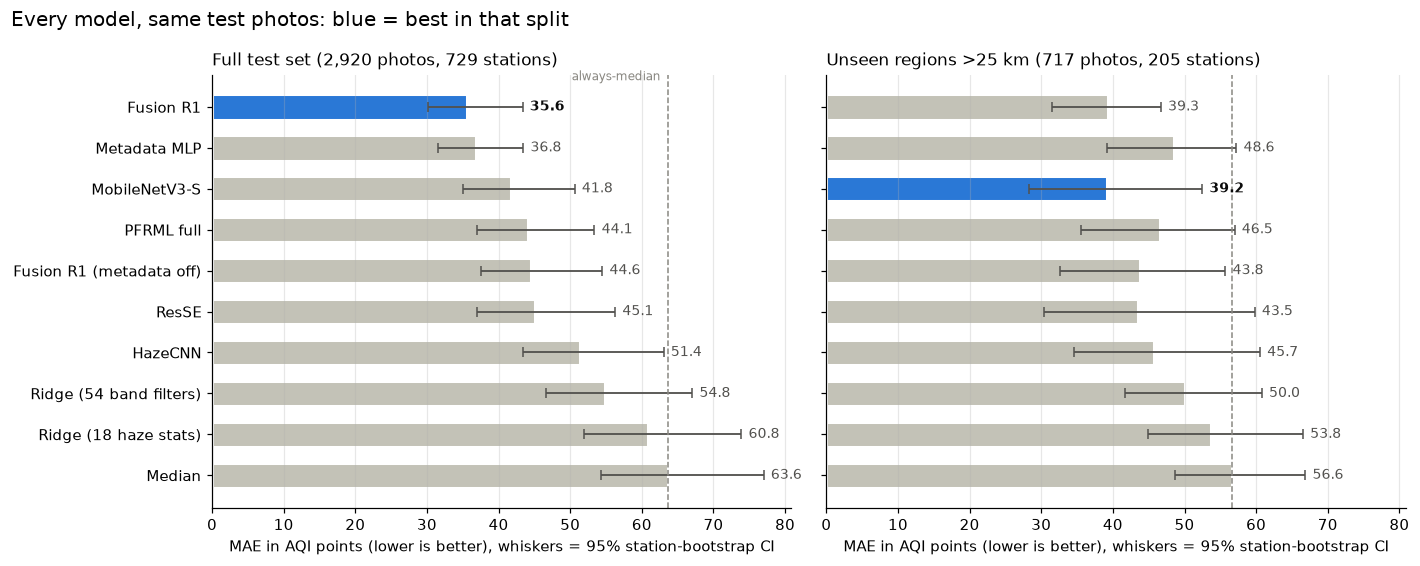

In [19]:
# COMPARE 1 - MAE with 95% station-bootstrap CI: full test set vs unseen regions (>25 km from any training station)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2), sharey=True, sharex=True)
for ax, (split, title, rows) in zip(axes, [('test', 'Full test set (2,920 photos, 729 stations)', test_rows),
                                           ('test_gt25km', 'Unseen regions >25 km (717 photos, 205 stations)', far_rows)]):
    rows = rows.loc[model_order[::-1]]
    best = rows['mae'].idxmin()
    colors = [BLUE if name == best else '#c3c2b7' for name in rows.index]
    ax.barh(rows.index, rows['mae'], color=colors, height=0.62, edgecolor='white', linewidth=2)
    ax.errorbar(rows['mae'], rows.index, xerr=[rows['mae'] - rows['mae_ci_low'], rows['mae_ci_high'] - rows['mae']],
                fmt='none', ecolor=INK2, elinewidth=1.2, capsize=3)
    for name, value, high in zip(rows.index, rows['mae'], rows['mae_ci_high']):
        ax.text(high + 1, name, f'{value:.1f}', va='center', fontsize=9, color=INK if name == best else INK2, fontweight='bold' if name == best else None)
    ax.axvline(rows.loc['Median', 'mae'], color=GRAY, linestyle='--', linewidth=1)
    ax.set_title(title, fontsize=11, loc='left')
    ax.set_xlabel('MAE in AQI points (lower is better), whiskers = 95% station-bootstrap CI')
    ax.grid(axis='y', visible=False)
axes[0].text(test_rows.loc['Median', 'mae'] - 1, len(model_order) - 0.35, 'always-median', ha='right', fontsize=8, color=GRAY)
fig.suptitle('Every model, same test photos: blue = best in that split', x=0.01, ha='left', fontsize=13)
plt.tight_layout()
plt.savefig(OUT_DIR / 'mae_comparison.png', bbox_inches='tight')
plt.show()

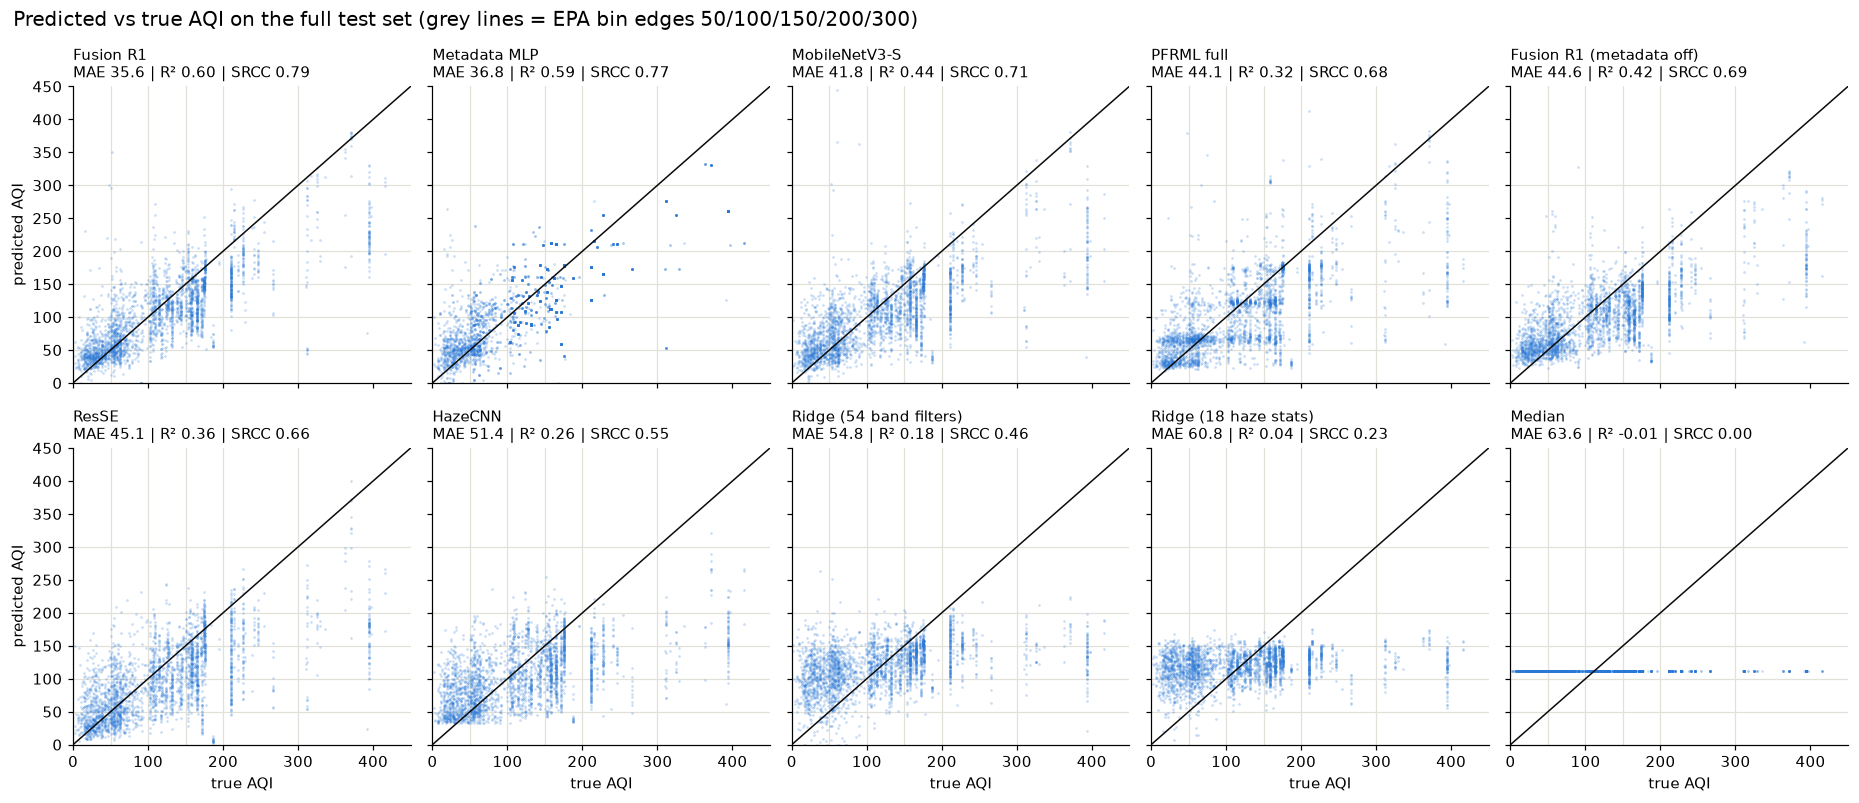

In [20]:
# COMPARE 2 - predicted vs true AQI for every model (perfect model = points on the diagonal; flat cloud = model guesses the average)
fig, axes = plt.subplots(2, 5, figsize=(17, 7.4), sharex=True, sharey=True)
bin_edges = [50, 100, 150, 200, 300]
for ax, name in zip(axes.ravel(), model_order):
    ax.scatter(y_test, predictions[name], s=3, alpha=0.25, color=BLUE, linewidths=0, rasterized=True)
    ax.plot([0, 500], [0, 500], color=INK, linewidth=1)
    for edge in bin_edges:
        ax.axvline(edge, color='#e1e0d9', linewidth=0.8, zorder=0)
        ax.axhline(edge, color='#e1e0d9', linewidth=0.8, zorder=0)
    row = test_rows.loc[name]
    ax.set_title(f"{name}\nMAE {row['mae']:.1f} | R² {row['r2']:.2f} | SRCC {row['srcc']:.2f}", fontsize=9.5, loc='left')
    ax.set(xlim=(0, 450), ylim=(0, 450))
    ax.grid(False)
for ax in axes[1]:
    ax.set_xlabel('true AQI')
for ax in axes[:, 0]:
    ax.set_ylabel('predicted AQI')
fig.suptitle('Predicted vs true AQI on the full test set (grey lines = EPA bin edges 50/100/150/200/300)', x=0.01, ha='left', fontsize=13)
plt.tight_layout()
plt.savefig(OUT_DIR / 'pred_vs_true.png', bbox_inches='tight')
plt.show()

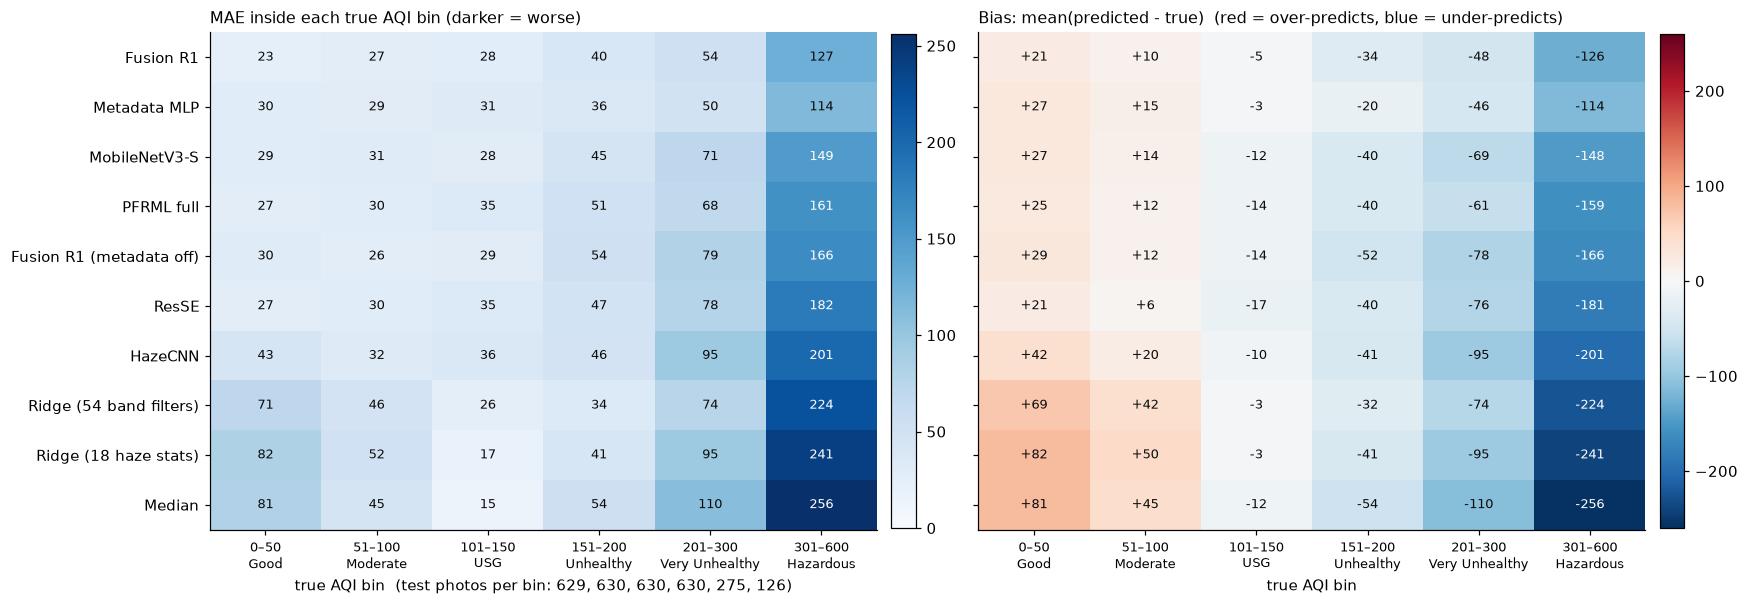

In [24]:
# COMPARE 3 - where does each model fail? MAE and signed bias (prediction - truth) inside each EPA AQI bin
bin_labels = [f'{label}\n{quality.replace("Unhealthy for Sensitive Groups", "USG")}' for label, quality in zip(EPA_BIN_LABELS, EPA_QUALITY_NAMES)]
per_bin_mae = pd.DataFrame({name: [np.abs(predictions[name] - y_test)[y_test_bin == b].mean() for b in range(6)] for name in model_order}, index=bin_labels).T
per_bin_bias = pd.DataFrame({name: [(predictions[name] - y_test)[y_test_bin == b].mean() for b in range(6)] for name in model_order}, index=bin_labels).T

fig, axes = plt.subplots(1, 2, figsize=(16, 5.6), sharey=True)
for ax, table, cmap, norm, title in [
    (axes[0], per_bin_mae, 'Blues', plt.Normalize(0, per_bin_mae.to_numpy().max()), 'MAE inside each true AQI bin (darker = worse)'),
    (axes[1], per_bin_bias, 'RdBu_r', plt.matplotlib.colors.TwoSlopeNorm(0, -260, 260), 'Bias: mean(predicted - true)  (red = over-predicts, blue = under-predicts)'),
]:
    image = ax.imshow(table.to_numpy(), cmap=cmap, norm=norm, aspect='auto')
    ax.set_xticks(range(6), table.columns, fontsize=8.5)
    ax.set_yticks(range(len(table)), table.index)
    ax.grid(False)
    for (r, c), value in np.ndenumerate(table.to_numpy()):
        shade = image.cmap(image.norm(value))
        ax.text(c, r, f'{value:+.0f}' if table is per_bin_bias else f'{value:.0f}', ha='center', va='center', fontsize=8.5,
                color='white' if (0.299 * shade[0] + 0.587 * shade[1] + 0.114 * shade[2]) < 0.55 else INK)
    ax.set_title(title, fontsize=10.5, loc='left')
    fig.colorbar(image, ax=ax, fraction=0.035, pad=0.02)
counts = np.bincount(y_test_bin, minlength=6)
axes[0].set_xlabel('true AQI bin  (test photos per bin: ' + ', '.join(map(str, counts)) + ')')
axes[1].set_xlabel('true AQI bin')
plt.tight_layout()
plt.savefig(OUT_DIR / 'per_bin_error.png', bbox_inches='tight')
plt.show()

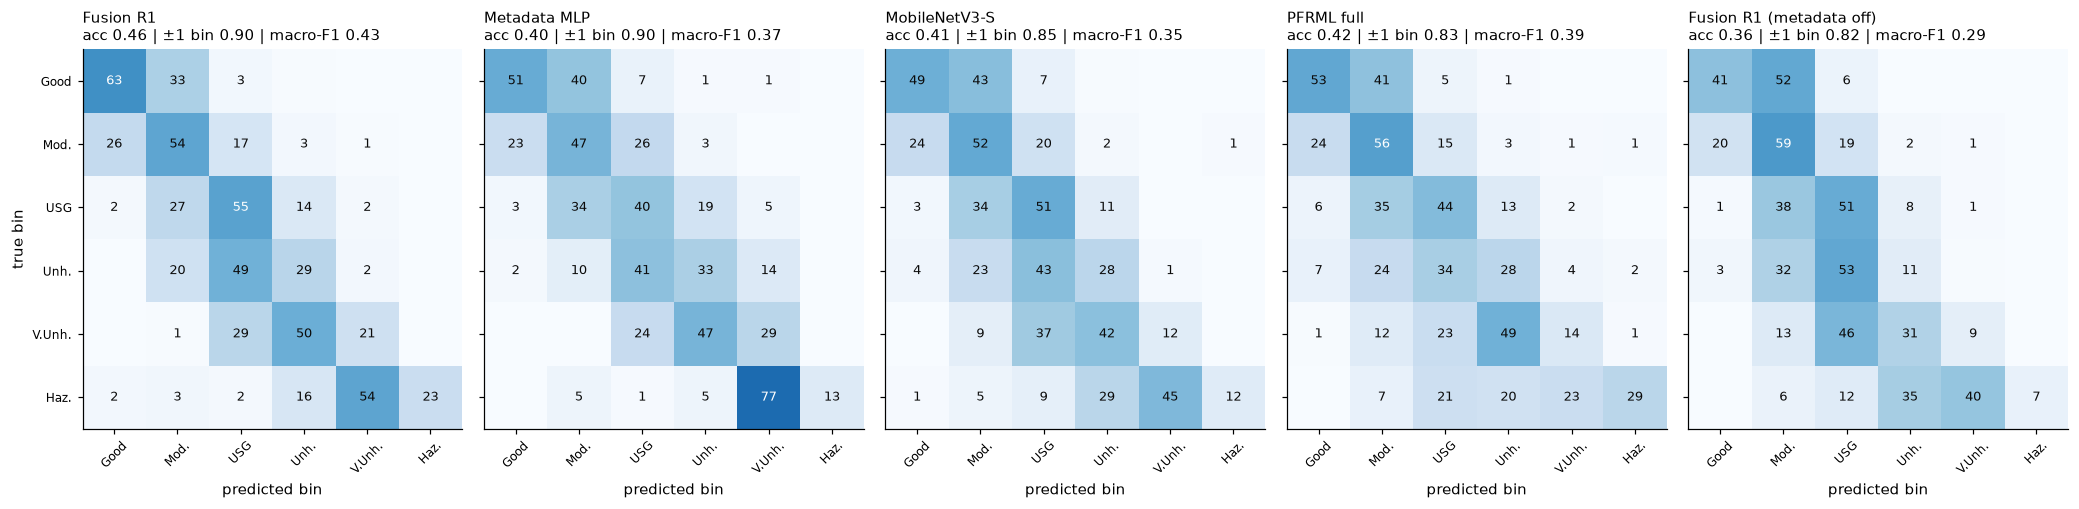

In [25]:
# COMPARE 4 - the 6 EPA categories: confusion matrices of the top 5 models (rows = true bin, % of that row; diagonal = correct)
from sklearn.metrics import confusion_matrix

top5 = model_order[:5]
short_bins = ['Good', 'Mod.', 'USG', 'Unh.', 'V.Unh.', 'Haz.']
fig, axes = plt.subplots(1, 5, figsize=(19, 4.2), sharey=True)
for ax, name in zip(axes, top5):
    matrix = confusion_matrix(y_test_bin, pred_bins[name], labels=range(6), normalize='true') * 100
    ax.imshow(matrix, cmap='Blues', vmin=0, vmax=100)
    for (r, c), value in np.ndenumerate(matrix):
        if value >= 0.5:
            ax.text(c, r, f'{value:.0f}', ha='center', va='center', fontsize=8.5, color='white' if value > 55 else INK)
    row = test_rows.loc[name]
    ax.set_title(f"{name}\nacc {row['acc']:.2f} | ±1 bin {row['pm1_acc']:.2f} | macro-F1 {row['macro_f1']:.2f}", fontsize=9.5, loc='left')
    ax.set_xticks(range(6), short_bins, fontsize=8, rotation=45)
    ax.set_yticks(range(6), short_bins, fontsize=8)
    ax.set_xlabel('predicted bin')
    ax.grid(False)
axes[0].set_ylabel('true bin')
plt.tight_layout()
plt.savefig(OUT_DIR / 'confusion_top5.png', bbox_inches='tight')
plt.show()

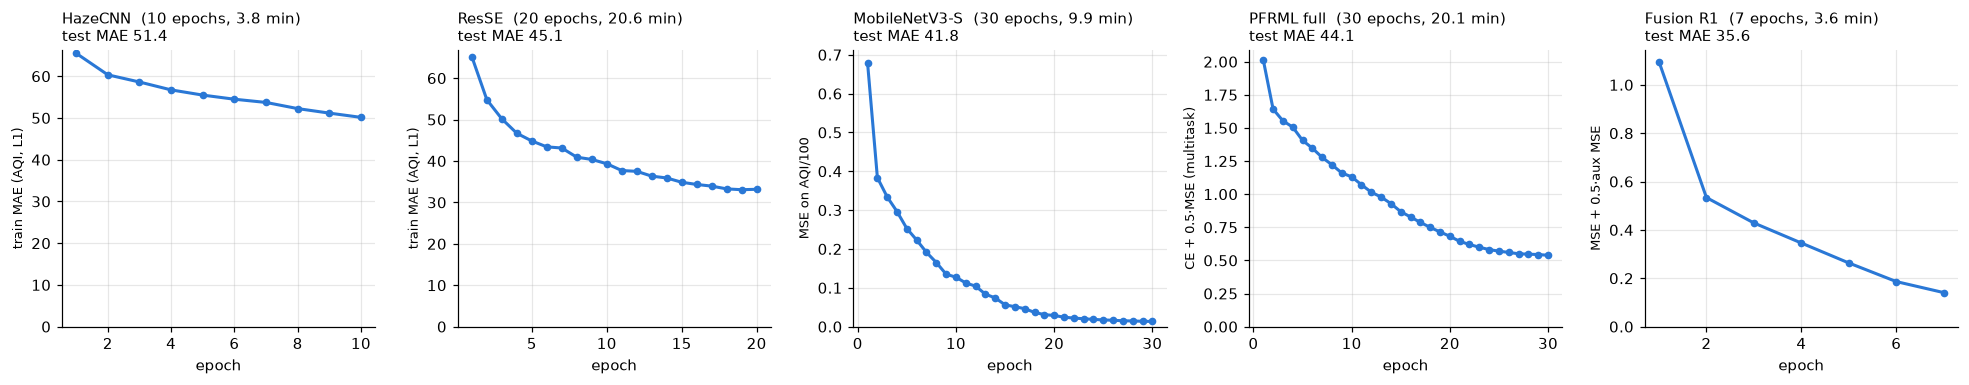

In [26]:
# COMPARE 5 - training curves of the neural models (each in its own loss units; no test data is used during training)
curve_units = {'HazeCNN': 'train MAE (AQI, L1)', 'ResSE': 'train MAE (AQI, L1)', 'MobileNetV3-S': 'MSE on AQI/100',
               'PFRML full': 'CE + 0.5·MSE (multitask)', 'Fusion R1': 'MSE + 0.5·aux MSE'}
fig, axes = plt.subplots(1, len(train_curves), figsize=(18, 3.6))
for ax, (name, curve) in zip(axes, train_curves.items()):
    epochs_axis = np.arange(1, len(curve) + 1)
    ax.plot(epochs_axis, curve, color=BLUE, linewidth=2, marker='o', markersize=4)
    ax.set_title(f"{name}  ({len(curve)} epochs, {model_info[name]['train_s'] / 60:.1f} min)\ntest MAE {test_rows.loc[name, 'mae']:.1f}", fontsize=9.5, loc='left')
    ax.set_xlabel('epoch')
    ax.set_ylabel(curve_units[name], fontsize=8.5)
    ax.set_ylim(bottom=0)
plt.tight_layout()
plt.savefig(OUT_DIR / 'training_curves.png', bbox_inches='tight')
plt.show()

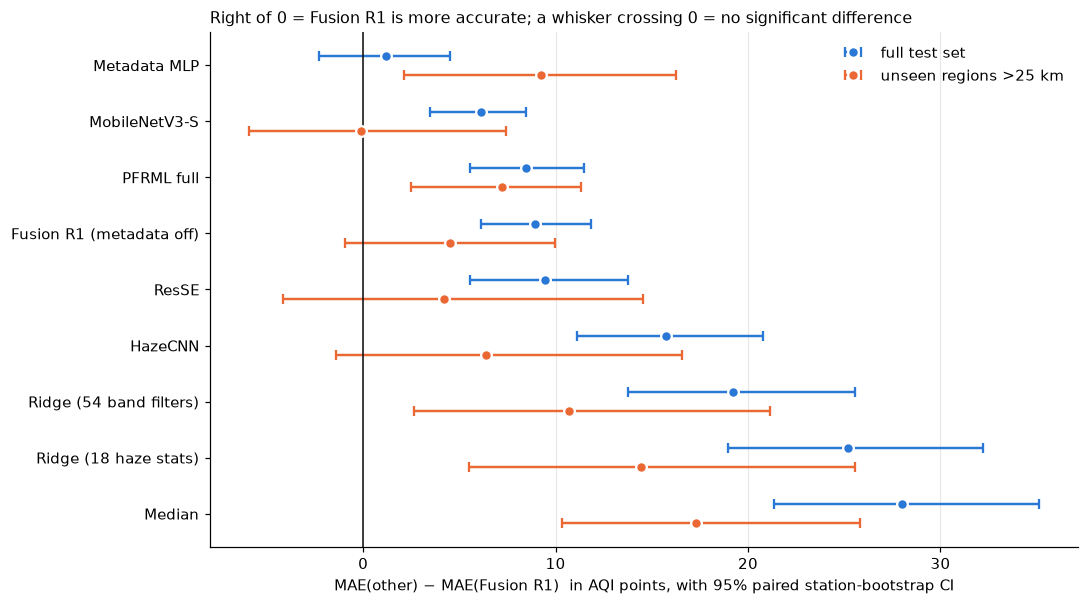

MAE(other) - MAE(winner)                 ci_low  \
split                                        test test_gt25km       test   
other model                                                                
Metadata MLP                             1.183015    9.240279  -2.299497   
MobileNetV3-S                            6.121879   -0.102754   3.459584   
PFRML full                               8.485196    7.225649   5.546465   
Fusion R1 (metadata off)                 8.944839    4.535264   6.104323   
ResSE                                    9.455441    4.189725   5.576831   
HazeCNN                                 15.749789    6.389214  11.097721   
Ridge (54 band filters)                 19.196325   10.713042  13.751964   
Ridge (18 haze stats)                   25.191859   14.449405  18.952685   
Median                                  27.987561    17.28138  21.332952   

                                        ci_high              \
split                    test_gt25km       test test_gt25km   
other model                                                   
Metadata MLP                2.099532   4.493413   16.257959   
MobileNetV3-S              -5.916442   8.462769    7.422495   
PFRML full                  2.507408  11.476452    11.33728   
Fusion R1 (metadata off)   -0.945433  11.843504     9.95953   
ResSE                      -4.143073  13.770153   14.559499   
HazeCNN                     -1.41835  20.791752   16.582726   
Ridge (54 band filters)     2.615579  25.578766   21.141108   
Ridge (18 haze stats)       5.508288  32.228236   25.543836   
Median                     10.352179  35.097424   25.821538   

                                            verdict                             
split                                          test                test_gt25km  
other model                                                                     
Metadata MLP              no significant difference           Fusion R1 better  
MobileNetV3-S                      Fusion R1 better  no significant difference  
PFRML full                         Fusion R1 better           Fusion R1 better  
Fusion R1 (metadata off)           Fusion R1 better  no significant difference  
ResSE                              Fusion R1 better  no significant difference  
HazeCNN                            Fusion R1 better  no significant difference  
Ridge (54 band filters)            Fusion R1 better           Fusion R1 better  
Ridge (18 haze stats)              Fusion R1 better           Fusion R1 better  
Median                             Fusion R1 better           Fusion R1 better

In [28]:
# COMPARE 6 - is the winner REALLY better? paired station bootstrap of MAE(other) - MAE(winner), 1,000 resamples of stations.
# Both models are scored on the same resampled stations, so the CI is about the difference itself. CI entirely > 0 -> winner significantly better.
from scripts.analysis.compare_final_models import paired_station_bootstrap_mae_diff

winner = model_order[0]
stations_all = test_df['station_id'].astype(str).to_numpy()
paired = []
for other in model_order[1:]:
    for split, mask in [('test', np.ones(len(test_df), bool)), ('test_gt25km', gt25_mask)]:
        diff, low, high = paired_station_bootstrap_mae_diff(y_test[mask], predictions[other][mask], predictions[winner][mask], stations_all[mask], n_boot=1000, seed=SEED)
        paired.append({'other model': other, 'split': split, 'MAE(other) - MAE(winner)': diff, 'ci_low': low, 'ci_high': high,
                       'verdict': f'{winner} better' if low > 0 else f'{other} better' if high < 0 else 'no significant difference'})
paired = pd.DataFrame(paired)

fig, ax = plt.subplots(figsize=(10, 5.6))
others = model_order[1:][::-1]
for offset, (split, color, label) in zip([0.17, -0.17], [('test', BLUE, 'full test set'), ('test_gt25km', ORANGE, 'unseen regions >25 km')]):
    rows = paired[paired['split'] == split].set_index('other model').loc[others]
    y = np.arange(len(others)) + offset
    ax.errorbar(rows['MAE(other) - MAE(winner)'], y, xerr=[rows['MAE(other) - MAE(winner)'] - rows['ci_low'], rows['ci_high'] - rows['MAE(other) - MAE(winner)']],
                fmt='o', color=color, ecolor=color, elinewidth=1.6, capsize=3, markersize=7, markeredgecolor='white', markeredgewidth=1.5, label=label)
ax.axvline(0, color=INK, linewidth=1)
ax.set_yticks(range(len(others)), others)
ax.grid(axis='y', visible=False)
ax.set_xlabel(f'MAE(other) − MAE({winner})  in AQI points, with 95% paired station-bootstrap CI')
ax.set_title(f'Right of 0 = {winner} is more accurate; a whisker crossing 0 = no significant difference', fontsize=10.5, loc='left')
ax.legend(loc='upper right', frameon=False)
plt.tight_layout()
plt.savefig(OUT_DIR / 'paired_bootstrap.png', bbox_inches='tight')
plt.show()
paired.pivot(index='other model', columns='split', values=['MAE(other) - MAE(winner)', 'ci_low', 'ci_high', 'verdict']).loc[model_order[1:]].round(2)

In [29]:
# ROBUSTNESS - one training run is one draw. The Metadata MLP moved 3.5 MAE between two runs of the SAME recipe (recorded 40.34 vs 36.83 here),
# so the top contenders are retrained with extra seeds. Same recipe, same epochs, only the seed (initialisation + data order + augmentation) changes.
seed_runs = [{'model': name, 'seed': SEED, 'test': test_rows.loc[name, 'mae'], 'test_gt25km': far_rows.loc[name, 'mae'], 'pred': predictions[name]}
             for name in ['Fusion R1', 'MobileNetV3-S', 'Metadata MLP']]


def add_seed_run(name, seed, y_pred):
    seed_runs.append({'model': name, 'seed': seed, 'test': np.abs(y_pred - y_test).mean(),
                      'test_gt25km': np.abs(y_pred - y_test)[gt25_mask].mean(), 'pred': np.clip(y_pred, 0, None)})
    print(f"{name:14s} seed {seed}: test MAE {seed_runs[-1]['test']:.2f} | >25km MAE {seed_runs[-1]['test_gt25km']:.2f}")


for seed in [43, 44, 45, 46]:
    pred, _, _ = _train_predict_metadata_mlp(meta_train, y_train, meta_test, cfg_meta, seed, device, OUT_DIR / 'checkpoints' / f'metadata_mlp_seed{seed}')
    add_seed_run('Metadata MLP', seed, pred)
for seed in [43, 44]:
    run = fit_repo_model(f'Fusion R1 seed{seed}', 'fusion_r1_mobilenetv3_s', 'configs/fusion_regression_only_neck.yaml', epochs=7, modality_dropout=0.0, seed=seed, verbose=False)
    add_seed_run('Fusion R1', seed, predict_repo(run)[0])
    run = fit_repo_model(f'MobileNetV3-S seed{seed}', 'mobilenetv3_s_pretrained', 'configs/default.yaml', epochs=30, seed=seed, verbose=False)
    add_seed_run('MobileNetV3-S', seed, predict_repo(run)[0])
    del run

seeds = pd.DataFrame(seed_runs)
seed_summary = seeds.groupby('model')[['test', 'test_gt25km']].agg(['mean', 'std', 'min', 'max', 'count']).loc[['Fusion R1', 'MobileNetV3-S', 'Metadata MLP']]
seed_summary.round(2)

Metadata MLP   seed 43: test MAE 35.79 | >25km MAE 46.70
Metadata MLP   seed 44: test MAE 37.36 | >25km MAE 47.72
Metadata MLP   seed 45: test MAE 36.98 | >25km MAE 46.97
Metadata MLP   seed 46: test MAE 36.20 | >25km MAE 45.80
Fusion R1      seed 43: test MAE 35.40 | >25km MAE 39.36
MobileNetV3-S  seed 43: test MAE 42.58 | >25km MAE 42.99
Fusion R1      seed 44: test MAE 35.14 | >25km MAE 38.96
MobileNetV3-S  seed 44: test MAE 42.66 | >25km MAE 41.97


Fusion R1 seed43 epoch 1:   0%|          | 0/256 [00:05<?, ?it/s]

Fusion R1 seed43 epoch 2:   0%|          | 0/256 [00:00<?, ?it/s]

Fusion R1 seed43 epoch 3:   0%|          | 0/256 [00:00<?, ?it/s]

Fusion R1 seed43 epoch 4:   0%|          | 0/256 [00:00<?, ?it/s]

Fusion R1 seed43 epoch 5:   0%|          | 0/256 [00:00<?, ?it/s]

... (66 outputs left out)

MobileNetV3-S seed44 epoch 28:   0%|          | 0/256 [00:00<?, ?it/s]

MobileNetV3-S seed44 epoch 29:   0%|          | 0/256 [00:00<?, ?it/s]

MobileNetV3-S seed44 epoch 30:   0%|          | 0/256 [00:00<?, ?it/s]

test                           test_gt25km               \
                mean   std    min    max count        mean   std    min   
model                                                                     
Fusion R1      35.39  0.25  35.14  35.65     3       39.21  0.22  38.96   
MobileNetV3-S  42.34  0.49  41.77  42.66     3       41.39  1.95  39.21   
Metadata MLP   36.63  0.63  35.79  37.36     5       47.15  1.04  45.80   

                            
                 max count  
model                       
Fusion R1      39.36     3  
MobileNetV3-S  42.99     3  
Metadata MLP   48.55     5

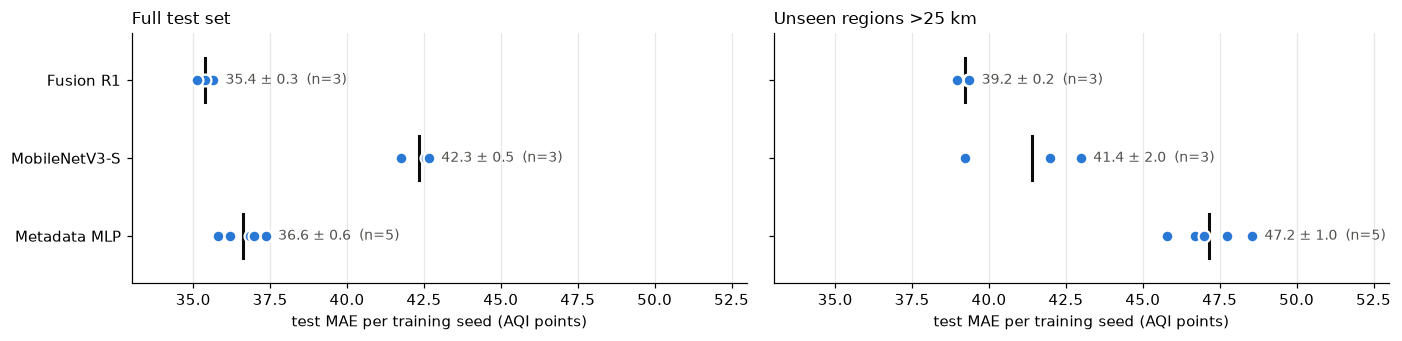

,comparison,split,MAE difference (seed-averaged),ci_low,ci_high,Fusion R1 significantly better
0,MobileNetV3-S - Fusion R1,test,6.41,3.52,9.25,True
1,MobileNetV3-S - Fusion R1,test_gt25km,0.88,-6.28,9.59,False
2,Metadata MLP - Fusion R1,test,1.56,-1.55,4.69,False
3,Metadata MLP - Fusion R1,test_gt25km,7.93,1.80,13.79,True


In [30]:
# ROBUSTNESS - every seed as a dot (vertical tick = mean over seeds), then a paired station bootstrap on SEED-AVERAGED predictions,
# which removes most of the run-to-run noise from the head-to-head comparison
seed_order = ['Fusion R1', 'MobileNetV3-S', 'Metadata MLP']
fig, axes = plt.subplots(1, 2, figsize=(13, 3.2), sharey=True, sharex=True)
for ax, split, title in zip(axes, ['test', 'test_gt25km'], ['Full test set', 'Unseen regions >25 km']):
    for row, name in enumerate(seed_order[::-1]):
        values = seeds.loc[seeds['model'] == name, split].to_numpy()
        ax.scatter(values, np.full(len(values), row), s=60, color=BLUE, edgecolor='white', linewidth=1.5, zorder=3)
        ax.plot([values.mean()] * 2, [row - 0.28, row + 0.28], color=INK, linewidth=2)
        ax.text(values.max() + 0.4, row, f'{values.mean():.1f} ± {values.std(ddof=1):.1f}  (n={len(values)})', va='center', fontsize=9, color=INK2)
    ax.set_yticks(range(len(seed_order)), seed_order[::-1])
    ax.set_title(title, fontsize=11, loc='left')
    ax.set_xlabel('test MAE per training seed (AQI points)')
    ax.grid(axis='y', visible=False)
    ax.set_ylim(-0.6, len(seed_order) - 0.4)
axes[0].set_xlim(33, 53)
plt.tight_layout()
plt.savefig(OUT_DIR / 'seed_robustness.png', bbox_inches='tight')
plt.show()

seed_mean_pred = {name: np.mean(np.stack(seeds.loc[seeds['model'] == name, 'pred'].to_list()), axis=0) for name in seed_order}
seed_paired = []
for other in seed_order[1:]:
    for split, mask in [('test', np.ones(len(test_df), bool)), ('test_gt25km', gt25_mask)]:
        diff, low, high = paired_station_bootstrap_mae_diff(y_test[mask], seed_mean_pred[other][mask], seed_mean_pred['Fusion R1'][mask], stations_all[mask], n_boot=1000, seed=SEED)
        seed_paired.append({'comparison': f'{other} - Fusion R1', 'split': split, 'MAE difference (seed-averaged)': diff, 'ci_low': low, 'ci_high': high,
                            'Fusion R1 significantly better': low > 0})
seed_paired = pd.DataFrame(seed_paired)
seed_paired.round(2)

largest difference between live and batch predictions: 0.000 AQI


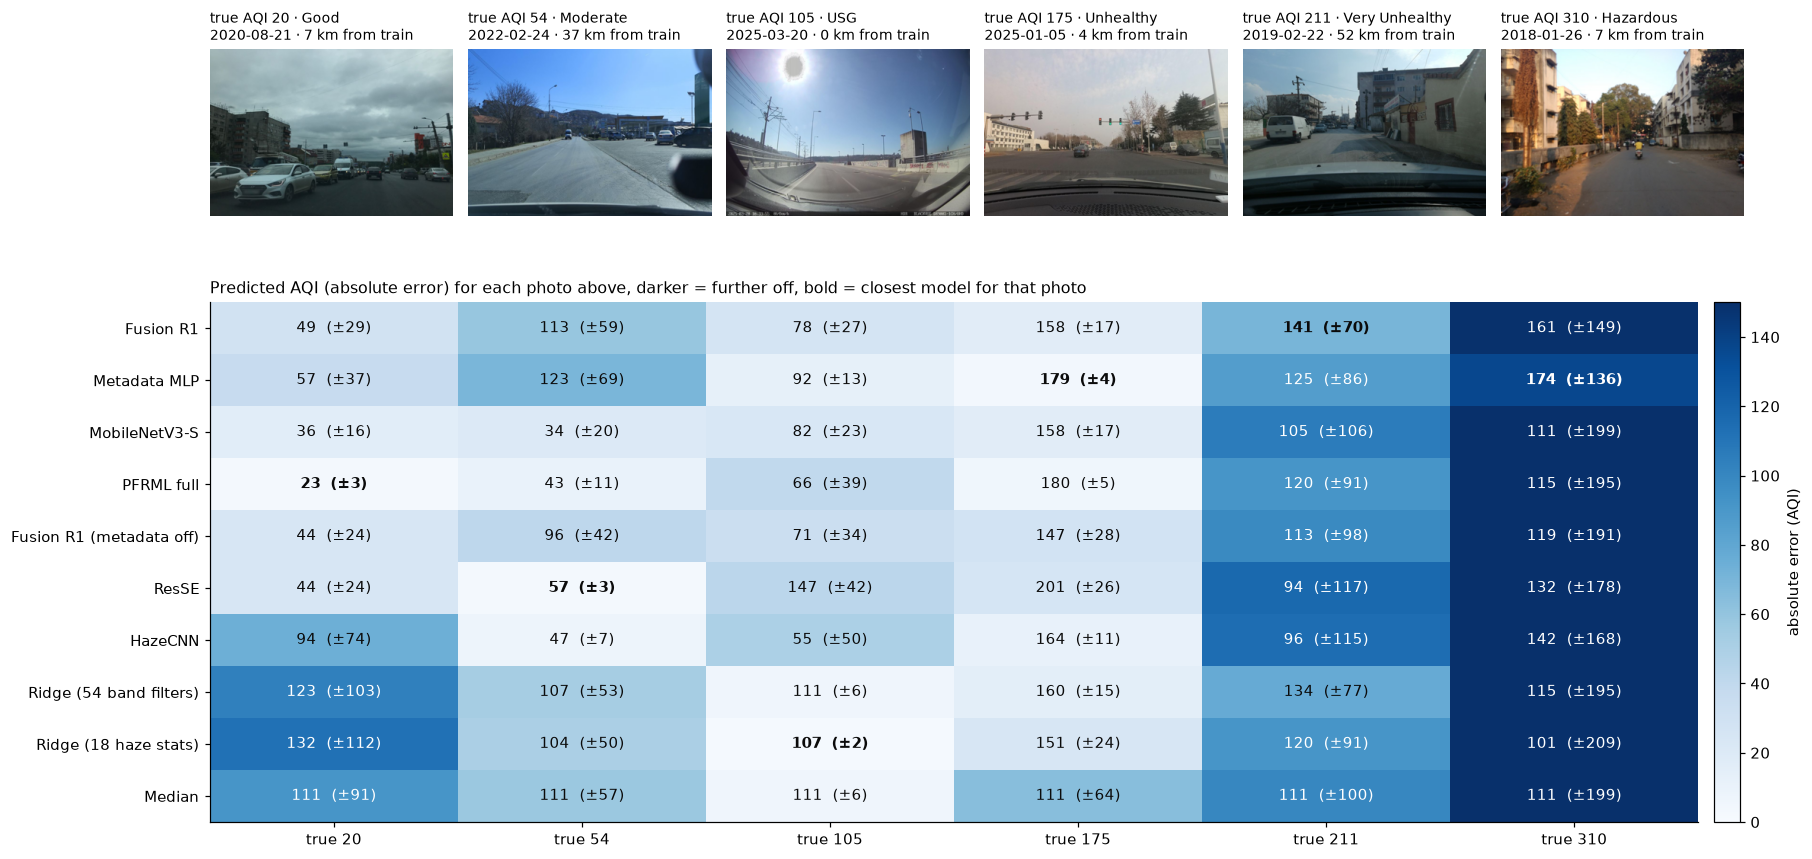

,0–50 (20),51–100 (54),101–150 (105),151–200 (175),201–300 (211),301–600 (310)
Fusion R1,49.0,113.0,78.0,158.0,141.0,161.0
Metadata MLP,57.0,123.0,92.0,179.0,125.0,174.0
MobileNetV3-S,36.0,34.0,82.0,158.0,105.0,111.0
PFRML full,23.0,43.0,66.0,180.0,120.0,115.0
Fusion R1 (metadata off),44.0,96.0,71.0,147.0,113.0,119.0
ResSE,44.0,57.0,147.0,201.0,94.0,132.0
HazeCNN,94.0,47.0,55.0,164.0,96.0,142.0
Ridge (54 band filters),123.0,107.0,111.0,160.0,134.0,115.0
Ridge (18 haze stats),132.0,104.0,107.0,151.0,120.0,101.0
Median,111.0,111.0,111.0,111.0,111.0,111.0


In [32]:
# SAMPLES - one random test photo per EPA category, every trained model predicts it LIVE from the photo (+ location/month where the model uses it)
sample_df = test_df.groupby('aqi_bin', group_keys=False).sample(1, random_state=SEED).sort_values('pm25').reset_index(drop=True)
sample_index = pd.Index(test_df['image_id']).get_indexer(sample_df['image_id'])  # their rows in test_df, in sample order
sample_paths = [Path('datasets/test/images') / name for name in sample_df['filename']]

with torch.no_grad():
    big = torch.stack([get_eval_transforms(224)(Image.open(p).convert('RGB')) for p in sample_paths]).to(device)      # 224 x 224, ImageNet-normalised
    small = torch.stack([torch.from_numpy(load_small(p).copy()).permute(2, 0, 1) for p in sample_paths])                    # 144 x 192, uint8 (notebook-3 CNNs)
    meta = torch.from_numpy(encode_metadata_features(sample_df['latitude'], sample_df['longitude'], sample_df['captured_at'])).to(device)
    haze = __import__('train')._extract_haze_matrix(sample_df, Path('datasets/test/images'), load_config('configs/default.yaml', overrides={'data.num_workers': 0}), device)
    band = sample_df[['image_id']].merge(band_features, on='image_id')[band_columns]                                  # notebook-2 features of these photos
    live = {
        'Median': median_model.predict(len(sample_df)),
        'Ridge (18 haze stats)': haze_ridge.predict(haze),
        'Ridge (54 band filters)': band_ridge.predict(band),
        'Metadata MLP': (metadata_mlp(meta) * 100).cpu().numpy(),
        'HazeCNN': predict_small(haze_cnn, small),
        'ResSE': predict_small(resse, small),
        'MobileNetV3-S': (run_e2['model'](big) * 100).cpu().numpy(),
        'PFRML full': (run_pfrml['model'](big).reg_pred * 100).cpu().numpy(),
        'Fusion R1': (run_fusion['model'](big, metadata=meta).reg_pred * 100).cpu().numpy(),
        'Fusion R1 (metadata off)': (run_fusion['model'](big, metadata=meta, metadata_off=True).reg_pred * 100).cpu().numpy(),
    }
live = pd.DataFrame({name: np.clip(values, 0, None) for name, values in live.items()}).T.loc[model_order]
live.columns = [f"{q} ({aqi:.0f})" for q, aqi in zip(sample_df['pm25_bin'], sample_df['pm25'])]

# the live single-photo predictions must match the batch test-set predictions scored above
drift = max(np.abs(live.loc[name].to_numpy() - predictions[name][sample_index]).max() for name in model_order)
print(f'largest difference between live and batch predictions: {drift:.3f} AQI')

fig = plt.figure(figsize=(18, 9.6))
grid = fig.add_gridspec(2, len(sample_df), height_ratios=[1, 2.1], hspace=0.12, wspace=0.06)
for col, (path, row) in enumerate(zip(sample_paths, sample_df.itertuples())):
    ax = fig.add_subplot(grid[0, col])
    ax.imshow(Image.open(path).convert('RGB').resize((320, 220)))
    category = EPA_QUALITY_NAMES[row.aqi_bin].replace('Unhealthy for Sensitive Groups', 'USG')
    ax.set_title(f"true AQI {row.pm25:.0f} · {category}\n{row.captured_at} · {row.nearest_train_km:.0f} km from train", fontsize=9, loc='left')
    ax.axis('off')
ax = fig.add_subplot(grid[1, :])
errors = np.abs(live.to_numpy() - sample_df['pm25'].to_numpy()[None, :])
image = ax.imshow(errors, cmap='Blues', vmin=0, vmax=150, aspect='auto')
for (r, c), err in np.ndenumerate(errors):
    ax.text(c, r, f'{live.iat[r, c]:.0f}  (±{err:.0f})', ha='center', va='center', fontsize=9.5, color='white' if err > 85 else INK,
            fontweight='bold' if err == errors[:, c].min() else None)
ax.set_xticks(range(len(sample_df)), [f'true {aqi:.0f}' for aqi in sample_df['pm25']])
ax.set_yticks(range(len(model_order)), model_order)
ax.grid(False)
ax.set_title('Predicted AQI (absolute error) for each photo above, darker = further off, bold = closest model for that photo', fontsize=10.5, loc='left')
fig.colorbar(image, ax=ax, fraction=0.02, pad=0.01, label='absolute error (AQI)')
plt.savefig(OUT_DIR / 'samples.png', bbox_inches='tight')
plt.show()
live.round(0)

In [34]:
# FINAL VERDICT - every number below is read from the results computed in this notebook
import textwrap


def mae(name, split='test'):
    return board.query('model == @name and split == @split')['mae'].iloc[0]


def r2(name, split='test'):
    return board.query('model == @name and split == @split')['r2'].iloc[0]


def seed_stat(name, split, stat):
    return seeds.loc[seeds['model'] == name, split].agg(stat)


def seed_diff(other, split):
    return seed_paired.query('comparison == @other + " - Fusion R1" and split == @split').iloc[0]


image_only = [m for m in model_order if model_info[m]['uses'] == 'image']
best_image = min(image_only, key=mae)
from_scratch = [m for m in model_order if model_info[m]['family'] == 'CNN from scratch']
handcrafted = [m for m in model_order if model_info[m]['family'] == 'handcrafted']
beats_winner = paired[paired['ci_high'] < 0]
meta_gain_test = mae('Fusion R1 (metadata off)') - mae('Fusion R1')
meta_gain_far = mae('Fusion R1 (metadata off)', 'test_gt25km') - mae('Fusion R1', 'test_gt25km')
hazard = per_bin_bias.iloc[:, 5]

scorecard = pd.DataFrame({
    'test MAE': test_rows['mae'], '>25km MAE': far_rows['mae'],
    'verdict': {
        'Fusion R1': 'WINNER: best on the full test set, tied-best on unseen regions, never significantly beaten, stable across seeds',
        'Metadata MLP': 'location shortcut: as good as fusion near known stations, collapses beyond 25 km (R² < 0)',
        'MobileNetV3-S': 'best image-only model: ties the winner far from training stations, clearly worse overall',
        'PFRML full': 'prototype branch hurts regression: worse than the plain MobileNetV3-S it is built on',
        'Fusion R1 (metadata off)': 'ablation: the fusion image branch alone, measures what location + month add',
        'ResSE': 'best from-scratch CNN: beats HazeCNN and every handcrafted model, loses to ImageNet pretraining',
        'HazeCNN': 'small from-scratch CNN: still improving at epoch 10, under-fitted',
        'Ridge (54 band filters)': 'best handcrafted model: real but weak signal',
        'Ridge (18 haze stats)': 'physics statistics alone barely beat the median',
        'Median': 'floor: no information at all',
    },
}).loc[model_order]
scorecard.to_csv(OUT_DIR / 'scorecard.csv')
seeds.drop(columns='pred').to_csv(OUT_DIR / 'seed_runs.csv', index=False)
paired.to_csv(OUT_DIR / 'paired_bootstrap.csv', index=False)

verdict = [
    f"WINNER: {winner}  (MobileNetV3-S image branch + DCM/Transformer neck, fused with location + month)",
    f"  full test MAE {mae(winner):.1f} (R² {r2(winner):.2f}), unseen regions >25 km MAE {mae(winner, 'test_gt25km'):.1f} (R² {r2(winner, 'test_gt25km'):.2f}); "
    f"over {int(seed_stat(winner, 'test', 'count'))} seeds {seed_stat(winner, 'test', 'mean'):.1f} ± {seed_stat(winner, 'test', 'std'):.1f} and "
    f"{seed_stat(winner, 'test_gt25km', 'mean'):.1f} ± {seed_stat(winner, 'test_gt25km', 'std'):.1f}.",
    f"  {'No model is significantly more accurate than it on either split' if beats_winner.empty else 'Significantly beaten by: ' + ', '.join(beats_winner['other model'])} "
    f"(paired station bootstrap, 1,000 resamples). It is the only model that is at or near the top on BOTH splits.",
    "",
    "WHY THE OTHERS LOSE",
    f"1. Metadata shortcut. The Metadata MLP never sees a pixel, yet reaches {mae('Metadata MLP'):.1f} on the full test set "
    f"(seed mean {seed_stat('Metadata MLP', 'test', 'mean'):.1f}; difference to fusion {seed_diff('Metadata MLP', 'test')['MAE difference (seed-averaged)']:+.1f}, "
    f"CI [{seed_diff('Metadata MLP', 'test')['ci_low']:.1f}, {seed_diff('Metadata MLP', 'test')['ci_high']:.1f}], not significant) because {(~gt25_mask).mean():.0%} of test photos "
    f"were taken within 25 km of a training photo, so 'what is the usual AQI here in this month' is already a strong answer. "
    f"Beyond 25 km it falls to {mae('Metadata MLP', 'test_gt25km'):.1f} (R² {r2('Metadata MLP', 'test_gt25km'):.2f}, worse than predicting a constant), "
    f"while {winner} holds {mae(winner, 'test_gt25km'):.1f}: seed-averaged gap {seed_diff('Metadata MLP', 'test_gt25km')['MAE difference (seed-averaged)']:+.1f} "
    f"[{seed_diff('Metadata MLP', 'test_gt25km')['ci_low']:.1f}, {seed_diff('Metadata MLP', 'test_gt25km')['ci_high']:.1f}], significant.",
    f"2. Images alone. The best image-only model is {best_image} ({mae(best_image):.1f}); fusion beats it by "
    f"{seed_diff('MobileNetV3-S', 'test')['MAE difference (seed-averaged)']:.1f} [{seed_diff('MobileNetV3-S', 'test')['ci_low']:.1f}, {seed_diff('MobileNetV3-S', 'test')['ci_high']:.1f}] "
    f"on the full test set, but far from training stations the two are statistically tied "
    f"({seed_diff('MobileNetV3-S', 'test_gt25km')['MAE difference (seed-averaged)']:+.1f} [{seed_diff('MobileNetV3-S', 'test_gt25km')['ci_low']:.1f}, {seed_diff('MobileNetV3-S', 'test_gt25km')['ci_high']:.1f}]). "
    f"In a truly new region the photo carries the prediction; location only helps where the model has seen nearby stations.",
    f"3. Metadata ablation. Zeroing the location/month input of the trained fusion model costs {meta_gain_test:.1f} MAE on the full test set "
    f"but only {meta_gain_far:.1f} beyond 25 km, the same story from inside one model.",
    f"4. PFRML prototypes. PFRML full ({mae('PFRML full'):.1f} / {mae('PFRML full', 'test_gt25km'):.1f}) is worse than the plain MobileNetV3-S "
    f"({mae('MobileNetV3-S'):.1f} / {mae('MobileNetV3-S', 'test_gt25km'):.1f}); its predictions snap to prototype levels (horizontal bands in the scatter plot). "
    f"The winning fusion model uses the regression-only neck, without this prototype branch.",
    f"5. Pretraining > hand-made filters. From scratch, {from_scratch[0]} ({mae(from_scratch[0]):.1f}) beats {from_scratch[1]} ({mae(from_scratch[1]):.1f}), "
    f"and both beat the handcrafted Ridge models ({', '.join(f'{m} {mae(m):.1f}' for m in handcrafted)}) and the median ({mae('Median'):.1f}); "
    f"ImageNet-pretrained MobileNetV3-S is better again ({mae('MobileNetV3-S'):.1f}).",
    "",
    "WHAT NO MODEL SOLVES",
    f"- Hazardous air (AQI > 300, {int((y_test_bin == 5).sum())} test photos) is under-predicted by every model: mean bias from "
    f"{hazard.max():+.0f} ({hazard.idxmax()}) to {hazard.min():+.0f} ({hazard.idxmin()}). Only {int((train_df['aqi_bin'] == 5).sum())} training photos are that polluted, "
    f"so all models regress towards the middle; clean photos are over-predicted for the same reason.",
    f"- Exact category is right only {test_rows.loc[winner, 'acc']:.0%} of the time for the winner, but within one category {test_rows.loc[winner, 'pm1_acc']:.0%} of the time: "
    f"good for coarse alerts (clean / moderate / unhealthy), not for exact AQI.",
    f"- Run-to-run noise is real: the Metadata MLP scored {reproduction.query('model == \"Metadata MLP\" and split == \"test\"')['recorded MAE'].iloc[0]:.1f} in the recorded run "
    f"and {seed_stat('Metadata MLP', 'test', 'min'):.1f}-{seed_stat('Metadata MLP', 'test', 'max'):.1f} here with the same recipe; single-run gaps under ~2 MAE should not be trusted.",
    "",
    f"FINAL VERDICT: use {winner}. It is the most accurate model overall and keeps its accuracy in unseen regions, where the metadata-only shortcut fails. "
    f"If location is unavailable, fall back to {best_image}, which matches it far from known stations.",
]
for line in verdict:
    print(textwrap.fill(line, width=150, subsequent_indent='   ') if line else '')
scorecard.round(1)

WINNER: Fusion R1  (MobileNetV3-S image branch + DCM/Transformer neck, fused with location + month)
  full test MAE 35.6 (R² 0.60), unseen regions >25 km MAE 39.3 (R² 0.38); over 3 seeds 35.4 ± 0.3 and 39.2 ± 0.2.
  No model is significantly more accurate than it on either split (paired station bootstrap, 1,000 resamples). It is the only model that is at or near
   the top on BOTH splits.

WHY THE OTHERS LOSE
1. Metadata shortcut. The Metadata MLP never sees a pixel, yet reaches 36.8 on the full test set (seed mean 36.6; difference to fusion +1.6, CI [-1.5,
   4.7], not significant) because 75% of test photos were taken within 25 km of a training photo, so 'what is the usual AQI here in this month' is
   already a strong answer. Beyond 25 km it falls to 48.6 (R² -0.05, worse than predicting a constant), while Fusion R1 holds 39.3: seed-averaged gap
   +7.9 [1.8, 13.8], significant.
2. Images alone. The best image-only model is MobileNetV3-S (41.8); fusion beats it by 6.4 [3.5, 9.3] on 

,test MAE,>25km MAE,verdict
Fusion R1,35.6,39.3,"WINNER: best on the full test set, tied-best o..."
Metadata MLP,36.8,48.6,location shortcut: as good as fusion near know...
MobileNetV3-S,41.8,39.2,best image-only model: ties the winner far fro...
PFRML full,44.1,46.5,prototype branch hurts regression: worse than ...
Fusion R1 (metadata off),44.6,43.8,"ablation: the fusion image branch alone, measu..."
ResSE,45.1,43.5,best from-scratch CNN: beats HazeCNN and every...
HazeCNN,51.4,45.7,small from-scratch CNN: still improving at epo...
Ridge (54 band filters),54.8,50.0,best handcrafted model: real but weak signal
Ridge (18 haze stats),60.8,53.8,physics statistics alone barely beat the median
Median,63.6,56.6,floor: no information at all
